IMPORTING LIBRARIES

In [1]:
import numpy as np
import pandas as pd
import os
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Load dataset
# Keep Online_Retail.xlsx in the same folder as this notebook.
df = pd.read_excel("Online_Retail.xlsx")
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


DESCRIPTIVE ANALYSIS

DATA CLEANING


In [4]:
df.shape

(541909, 8)

In [5]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

In [6]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [7]:
# df.drop(df[df['CustomerID'].isnull()])
df.drop(df[df['CustomerID'].isnull()].index,inplace=True)

In [8]:
df.isnull().sum()


InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [9]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,406829.000000,406829,406829.000000,406829.000000
mean,12.061303,2011-07-10 16:30:57.879207,3.460471,15287.690570
min,-80995.000000,2010-12-01 08:26:00,0.000000,12346.000000
25%,2.000000,2011-04-06 15:02:00,1.250000,13953.000000
50%,5.000000,2011-07-31 11:48:00,1.950000,15152.000000
75%,12.000000,2011-10-20 13:06:00,3.750000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,248.693370,NaN,69.315162,1713.600303


In [10]:
df['Country'].value_counts().shape

(37,)

In [11]:
df.info()

<class 'pandas.DataFrame'>
Index: 406829 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    406829 non-null  object        
 1   StockCode    406829 non-null  object        
 2   Description  406829 non-null  object        
 3   Quantity     406829 non-null  int64         
 4   InvoiceDate  406829 non-null  datetime64[us]
 5   UnitPrice    406829 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      406829 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


CHECKING ON CATEGORICAL VARIABLES

In [12]:
df['StockCode'].value_counts().sort_values(ascending=False).head()


StockCode
85123A    2077
22423     1905
85099B    1662
84879     1418
47566     1416
Name: count, dtype: int64

In [13]:
df['StockCode'].unique()

array(['85123A', 71053, '84406B', ..., '90214Z', 90089, 23843],
      shape=(3684,), dtype=object)

In [14]:
df.duplicated().sum()

np.int64(5225)

In [15]:
df.drop_duplicates(inplace=True)

In [16]:
df.duplicated().sum()

np.int64(0)

REMOVING INCONSISTENT VALUES

In [17]:
df[df['Quantity']<0].shape[0]

#number of returns


8872

FEATURE ENGINEERING


In [18]:
df['Revenue']=df['Quantity']*df['UnitPrice']
df['Revenue'].shape


(401604,)

ANALYSIS ON CATEGORICAL VARIABLES

In [19]:
df['Country'].unique()
#There are around 37 different countries

<ArrowStringArray>
[      'United Kingdom',               'France',            'Australia',
          'Netherlands',              'Germany',               'Norway',
                 'EIRE',          'Switzerland',                'Spain',
               'Poland',             'Portugal',                'Italy',
              'Belgium',            'Lithuania',                'Japan',
              'Iceland',      'Channel Islands',              'Denmark',
               'Cyprus',               'Sweden',              'Austria',
               'Israel',              'Finland',               'Greece',
            'Singapore',              'Lebanon', 'United Arab Emirates',
         'Saudi Arabia',       'Czech Republic',               'Canada',
          'Unspecified',               'Brazil',                  'USA',
   'European Community',              'Bahrain',                'Malta',
                  'RSA']
Length: 37, dtype: str

In [20]:
df['Description'].value_counts().shape

#can see that there are specific 3896 descriptions for the data 

(3896,)

In [21]:
df['Description'].unique()


array(['WHITE HANGING HEART T-LIGHT HOLDER', 'WHITE METAL LANTERN',
       'CREAM CUPID HEARTS COAT HANGER', ...,
       'PINK CRYSTAL SKULL PHONE CHARM',
       'CREAM HANGING HEART T-LIGHT HOLDER',
       'PAPER CRAFT , LITTLE BIRDIE'], shape=(3896,), dtype=object)

CHECKING ON NUMERICAL VARIABLES/FEATURES

In [22]:
df.info()

<class 'pandas.DataFrame'>
Index: 401604 entries, 0 to 541908
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    401604 non-null  object        
 1   StockCode    401604 non-null  object        
 2   Description  401604 non-null  object        
 3   Quantity     401604 non-null  int64         
 4   InvoiceDate  401604 non-null  datetime64[us]
 5   UnitPrice    401604 non-null  float64       
 6   CustomerID   401604 non-null  float64       
 7   Country      401604 non-null  str           
 8   Revenue      401604 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(1), object(3), str(1)
memory usage: 35.7+ MB


In [23]:
df['InvoiceNo'].unique()

array([536365, 536366, 536367, ..., 581585, 581586, 581587],
      shape=(22190,), dtype=object)

In [24]:
num_features=[feature for feature in df.columns if df[feature].dtype!='O']
print(num_features)
num_features.remove('InvoiceDate')
num_features.remove('Country')

num_features.remove('CustomerID')

print(num_features)



['Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue']
['Quantity', 'UnitPrice', 'Revenue']


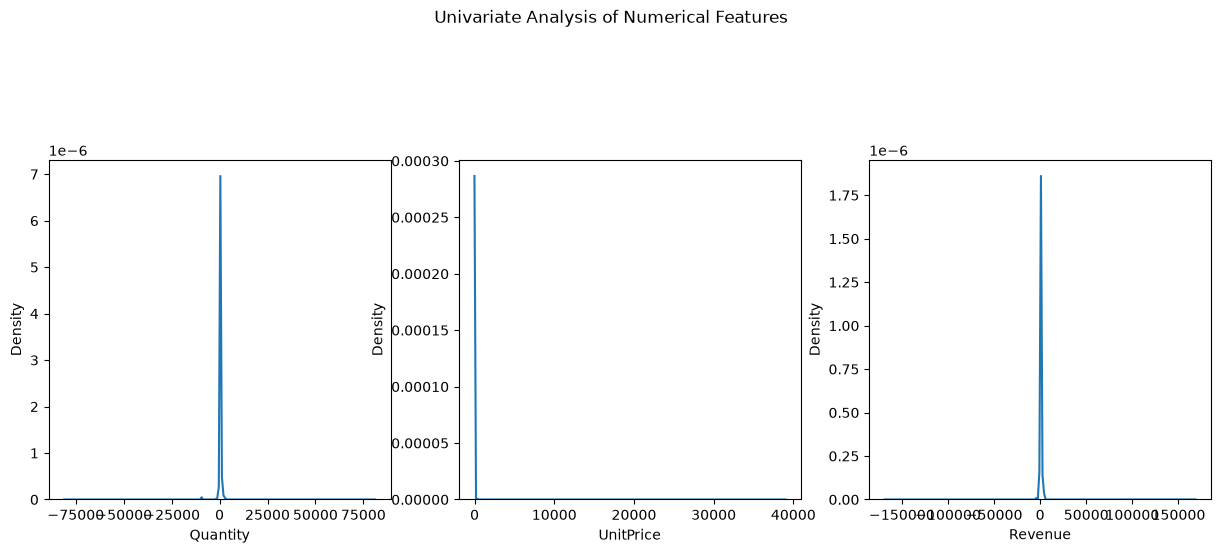

In [25]:
plt.figure(figsize=(15, 15))
plt.suptitle('Univariate Analysis of Numerical Features')



for i in range(len(num_features)):

    plt.subplot(3,3,i+1)
    sns.kdeplot(x=df[num_features[i]])
    plt.xlabel(num_features[i])
    

<Axes: xlabel='Quantity', ylabel='Density'>

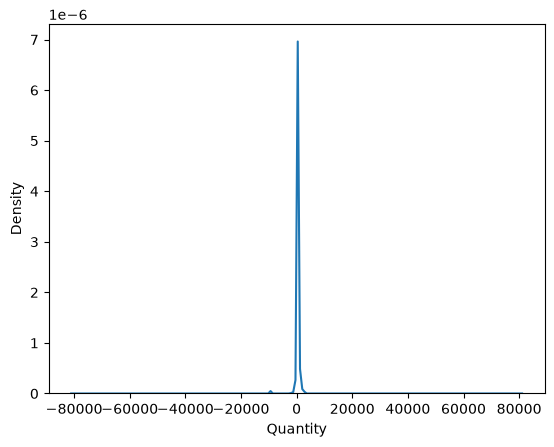

In [26]:
sns.kdeplot(x=df['Quantity'])


In [27]:
df[['Quantity']].describe()

,Quantity
count,401604.000000
mean,12.183273
std,250.283037
min,-80995.000000
25%,2.000000
50%,5.000000
75%,12.000000
max,80995.000000


In [28]:
df['Quantity'].quantile([0.75,0.9,0.95,0.99])

0.75     12.0
0.90     24.0
0.95     36.0
0.99    120.0
Name: Quantity, dtype: float64

In [29]:
df['Quantity'].min()

np.int64(-80995)

<Axes: xlabel='Quantity', ylabel='Density'>

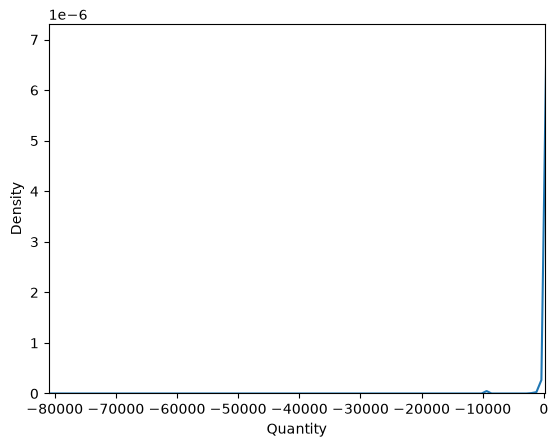

In [30]:
plt.xlim(df['Quantity'].min(),120)
sns.kdeplot(x=df['Quantity'])



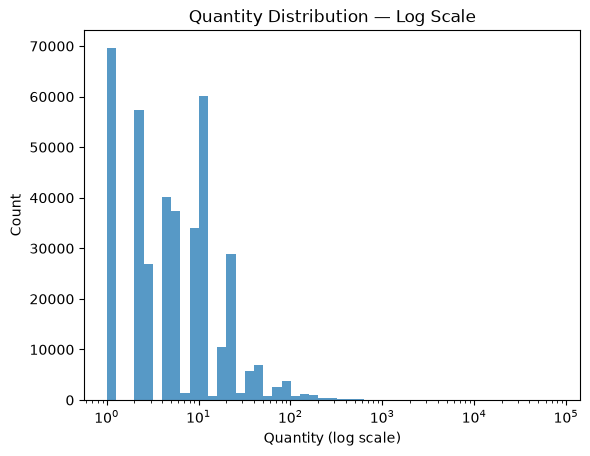

In [31]:
bins = np.logspace(
    0,
    np.log10(df["Quantity"].max()),
    50
)

sns.histplot(df["Quantity"], bins=bins)

plt.xscale("log")

plt.xlabel("Quantity (log scale)")
plt.ylabel("Count")
plt.title("Quantity Distribution — Log Scale")

plt.show()

In [32]:
#Could be a chance that there was some bulk order that happened for order of 10^3 

CHANGING BASED ON THE QUNATITY NUMBER

In [33]:
df_copy=df.drop(df[df['Quantity']>125].index)

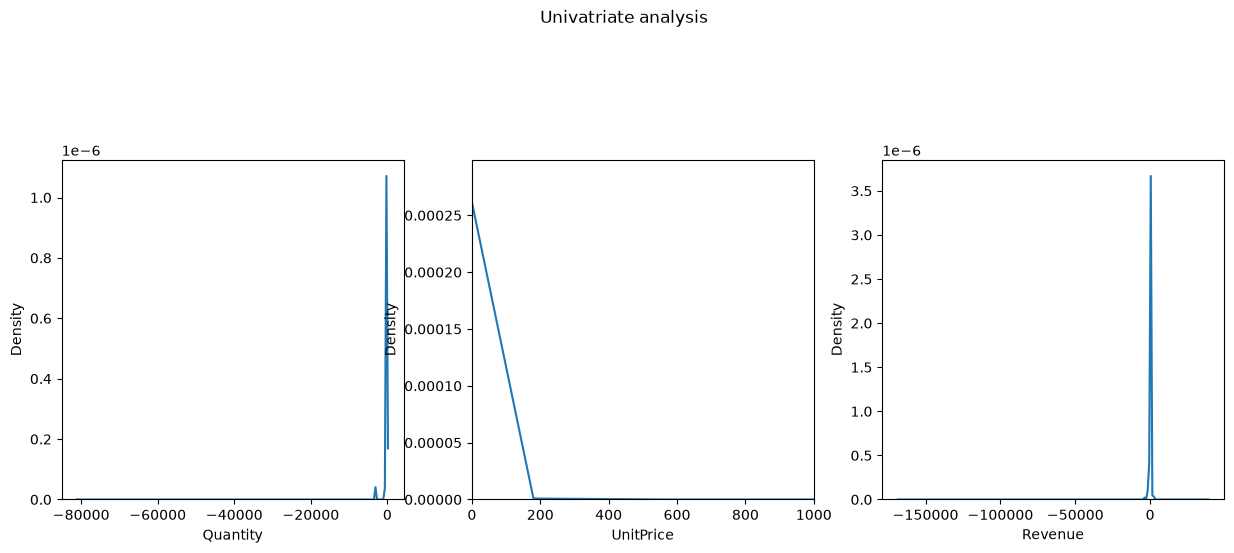

In [34]:
plt.figure(figsize=(15,15))
plt.suptitle("Univatriate analysis")

for i in range(len(num_features)):
    plt.subplot(3,3,i+1)
    sns.kdeplot(x=df_copy[num_features[i]])
    plt.xlabel(num_features[i])
    if num_features[i]=='UnitPrice':
        plt.xlim(0,1000)


In [35]:
df['UnitPrice'].quantile([0.75,0.9,0.95,0.99])


0.75     3.75
0.90     6.75
0.95     8.50
0.99    15.00
Name: UnitPrice, dtype: float64

In [36]:
df[df['UnitPrice']>15.00].describe()



,Quantity,InvoiceDate,UnitPrice,CustomerID,Revenue
count,3857.000000,3857,3857.000000,3857.000000,3857.000000
mean,1.723101,2011-07-08 08:56:58.802177,78.509362,14421.342753,38.712082
min,-12.000000,2010-12-01 08:45:00,15.050000,12348.000000,-38970.000000
25%,1.000000,2011-04-06 11:34:00,16.950000,12683.000000,16.950000
50%,1.000000,2011-07-19 15:13:00,18.000000,14096.000000,31.900000
75%,2.000000,2011-10-20 12:53:00,29.950000,15701.000000,50.000000
max,120.000000,2011-12-09 12:16:00,38970.000000,18283.000000,38970.000000
std,3.756263,NaN,707.480400,1768.896962,960.096630


In [37]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'Revenue'],
      dtype='str')

In [38]:
df[df['UnitPrice']==0].shape[0]

# Observing products having 0 unit price

40

In [39]:
df[df['UnitPrice']==0]

#Hypothesis: Zero priced transactions could mean that these were promotional products given away for free.
#Decision: keeping them as it is

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,2010-12-05 14:02:00,0.0,12647.0,Germany,0.0
33576,539263,22580,ADVENT CALENDAR GINGHAM SACK,4,2010-12-16 14:36:00,0.0,16560.0,United Kingdom,0.0
40089,539722,22423,REGENCY CAKESTAND 3 TIER,10,2010-12-21 13:45:00,0.0,14911.0,EIRE,0.0
47068,540372,22090,PAPER BUNTING RETROSPOT,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom,0.0
47070,540372,22553,PLASTERS IN TIN SKULLS,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom,0.0
56674,541109,22168,ORGANISER WOOD ANTIQUE WHITE,1,2011-01-13 15:10:00,0.0,15107.0,United Kingdom,0.0
86789,543599,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,16,2011-02-10 13:08:00,0.0,17560.0,United Kingdom,0.0
130188,547417,22062,CERAMIC BOWL WITH LOVE HEART DESIGN,36,2011-03-23 10:25:00,0.0,13239.0,United Kingdom,0.0
139453,548318,22055,MINI CAKE STAND HANGING STRAWBERY,5,2011-03-30 12:45:00,0.0,13113.0,United Kingdom,0.0
145208,548871,22162,HEART GARLAND RUSTIC PADDED,2,2011-04-04 14:42:00,0.0,14410.0,United Kingdom,0.0


In [40]:
print("min = ",df['UnitPrice'].min())
print("min = ",df['UnitPrice'].max())


min =  0.0
min =  38970.0


BUISNESS METRICS/KPIs


In [41]:

print("TOTAL REVENUE = $",df['Revenue'].sum())
print("TOTAL ORDERS = $",df['InvoiceNo'].unique().shape[0])
print("TOTAL UNITS SOLD = $",df['Quantity'].sum())



TOTAL REVENUE = $ 8278519.424
TOTAL ORDERS = $ 22190
TOTAL UNITS SOLD = $ 4892851


In [42]:
print("Unique Customers = ",df['CustomerID'].unique())
print("No. of Unique Customers = ",df['CustomerID'].unique().shape[0])


Unique Customers =  [17850. 13047. 12583. ... 13298. 14569. 12713.]
No. of Unique Customers =  4372


In [43]:
print("Average order value (AOV) = ",df["Revenue"].sum()/df['InvoiceNo'].unique().shape[0])

Average order value (AOV) =  373.07433186119874


In [44]:
print("Revenue per Customer = ",df["Revenue"].sum()/df['CustomerID'].unique().shape[0])

Revenue per Customer =  1893.5314327538883


In [45]:
Customer_order_numbers=df.groupby('CustomerID')['InvoiceNo'].nunique()
# print(Customer_order_numbers[Customer_order_numbers==1])
one_time_customers=Customer_order_numbers[Customer_order_numbers==1].shape[0]
print("ONE TIME VS REPEAT CUSTOMERS = ",one_time_customers," vs ",Customer_order_numbers.shape[0]-one_time_customers)


ONE TIME VS REPEAT CUSTOMERS =  1313  vs  3059


In [46]:
print("Average orders = ",df['InvoiceNo'].unique().shape[0]/df['CustomerID'].unique().shape[0])
revenue_spend_per_customer=df.groupby(df['CustomerID'])["Revenue"].sum()
print("Average spent by customers = ",revenue_spend_per_customer.mean())

Average orders =  5.07548032936871
Average spent by customers =  1893.5314327538883


Time-Based Sales Analysis

In [47]:
df["Month"]=pd.to_datetime(df['InvoiceDate']).dt.month
# df["Month"]=df['InvoiceDate'].dt.month
#making month column

df["Year"]=pd.to_datetime(df["InvoiceDate"]).dt.year
#making year column


In [48]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Month,Year
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,12,2010
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,2010
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,12,2010
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,2010
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,2010
...,...,...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,10.20,12,2011
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60,12,2011
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,12,2011
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,12,2011


In [49]:
df_copy=df[df['InvoiceDate']<'2011-12-01']
df_copy
#considering a 12 full month period 2010 decmeber to 2011 November since 2011 decemeber data is not complete

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Month,Year
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,12,2010
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,2010
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,12,2010
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,2010
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,2010
...,...,...,...,...,...,...,...,...,...,...,...
516379,C579886,22197,POPCORN HOLDER,-1,2011-11-30 17:39:00,0.85,15676.0,United Kingdom,-0.85,11,2011
516380,C579886,23146,TRIPLE HOOK ANTIQUE IVORY ROSE,-1,2011-11-30 17:39:00,3.29,15676.0,United Kingdom,-3.29,11,2011
516381,C579887,84946,ANTIQUE SILVER T-LIGHT GLASS,-1,2011-11-30 17:42:00,1.25,16717.0,United Kingdom,-1.25,11,2011
516382,C579887,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,-1,2011-11-30 17:42:00,7.95,16717.0,United Kingdom,-7.95,11,2011


In [50]:
#orders by month 
orders_per_month=df_copy.groupby(['Month'])['InvoiceNo'].nunique().reset_index()
orders_per_month

,Month,InvoiceNo
0,1,1236
1,2,1202
2,3,1619
3,4,1384
4,5,1849
5,6,1707
6,7,1593
7,8,1544
8,9,2078
9,10,2263


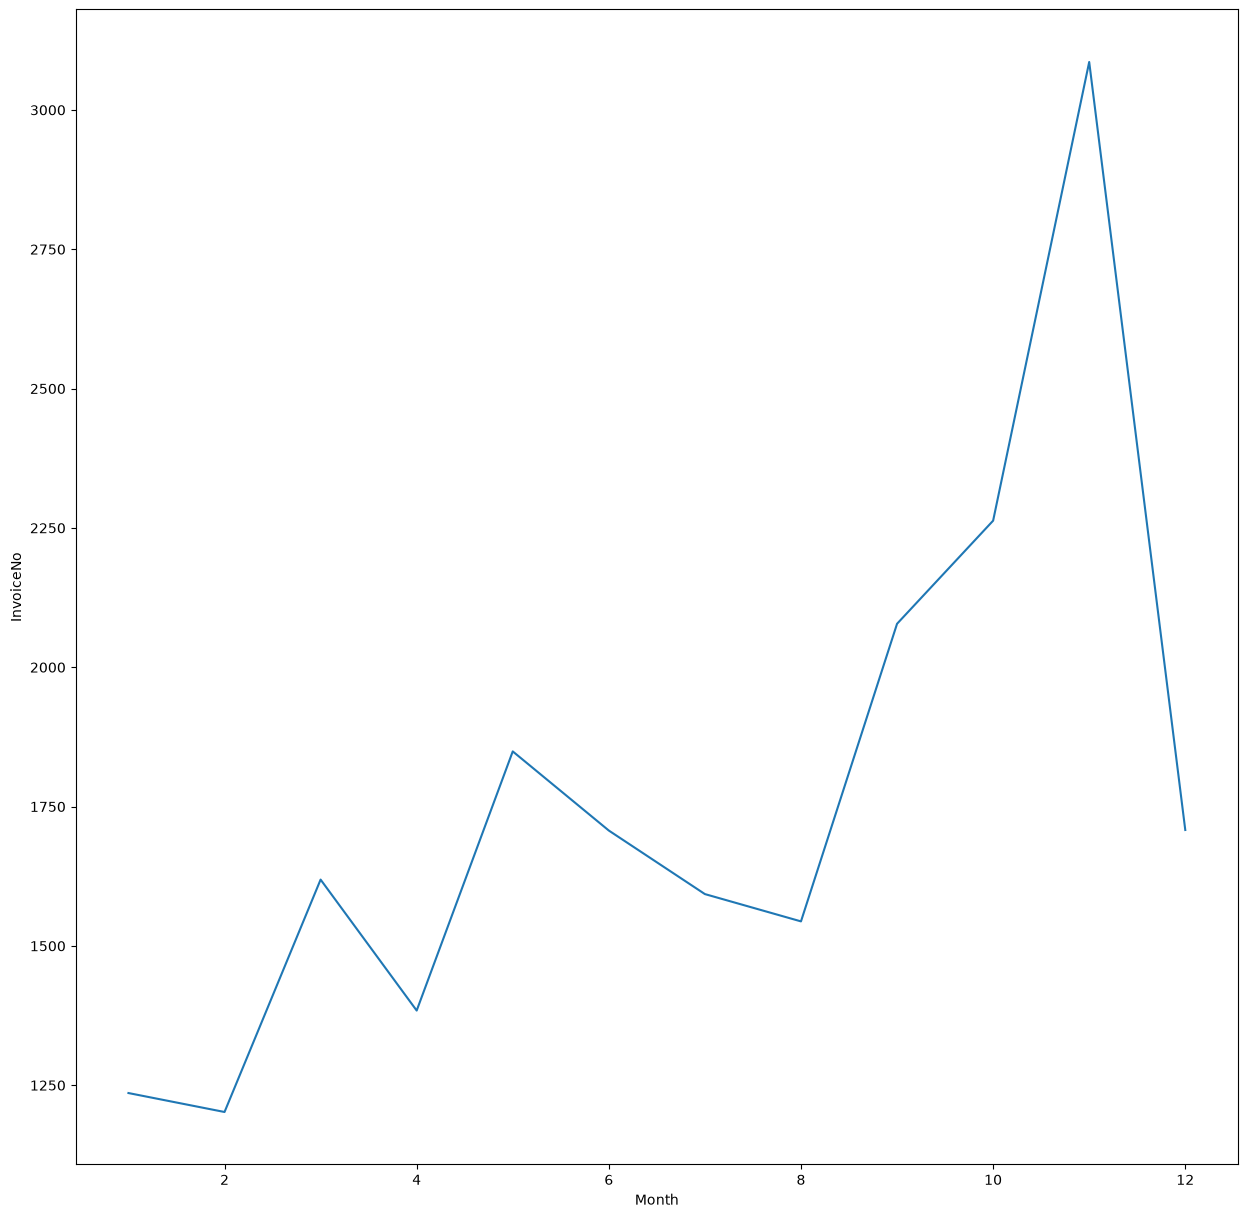

In [51]:
plt.figure(figsize=(15,15))
# plt.suptitle("Number of orders trend")
sns.lineplot(x=orders_per_month["Month"],y=orders_per_month["InvoiceNo"])
plt.show()


In [52]:
#revenue by month
revenue_per_month=df_copy.groupby(['Month'])['Revenue'].sum().reset_index()
revenue_per_month



,Month,Revenue
0,1,473731.900
1,2,435534.070
2,3,578576.210
3,4,425222.671
4,5,647011.670
5,6,606862.520
6,7,573112.321
7,8,615078.090
8,9,929356.232
9,10,973306.380


In [53]:
revenue_per_month['MoM%']=revenue_per_month['Revenue'].pct_change()*100
revenue_per_month


,Month,Revenue,MoM%
0,1,473731.900,NaN
1,2,435534.070,-8.063175
2,3,578576.210,32.842928
3,4,425222.671,-26.505331
4,5,647011.670,52.158319
5,6,606862.520,-6.205321
6,7,573112.321,-5.561424
7,8,615078.090,7.322434
8,9,929356.232,51.095649
9,10,973306.380,4.729096


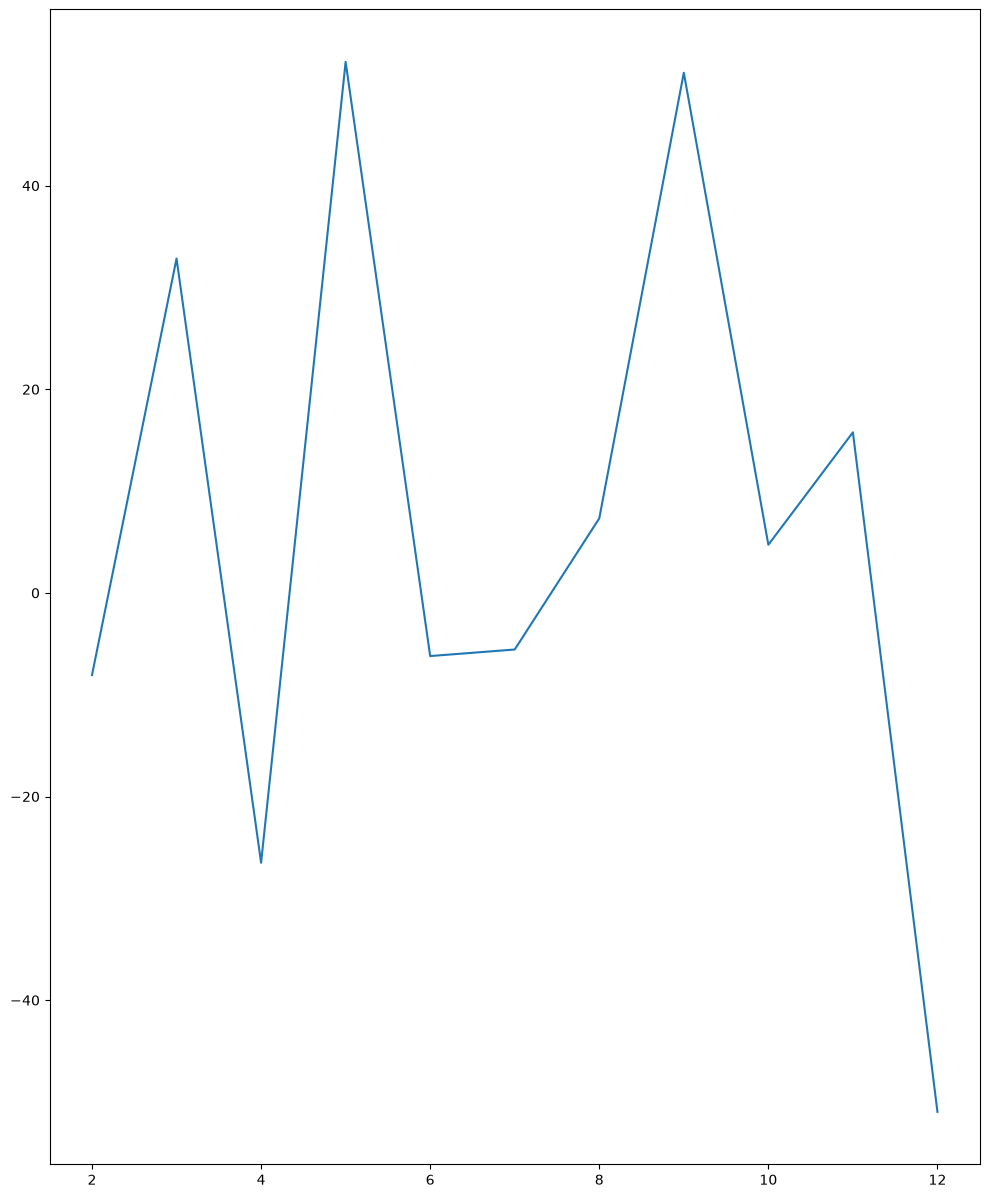

In [54]:
plt.figure(figsize=(12,15))
plt.plot(revenue_per_month['Month'],revenue_per_month['MoM%'])
plt.show()

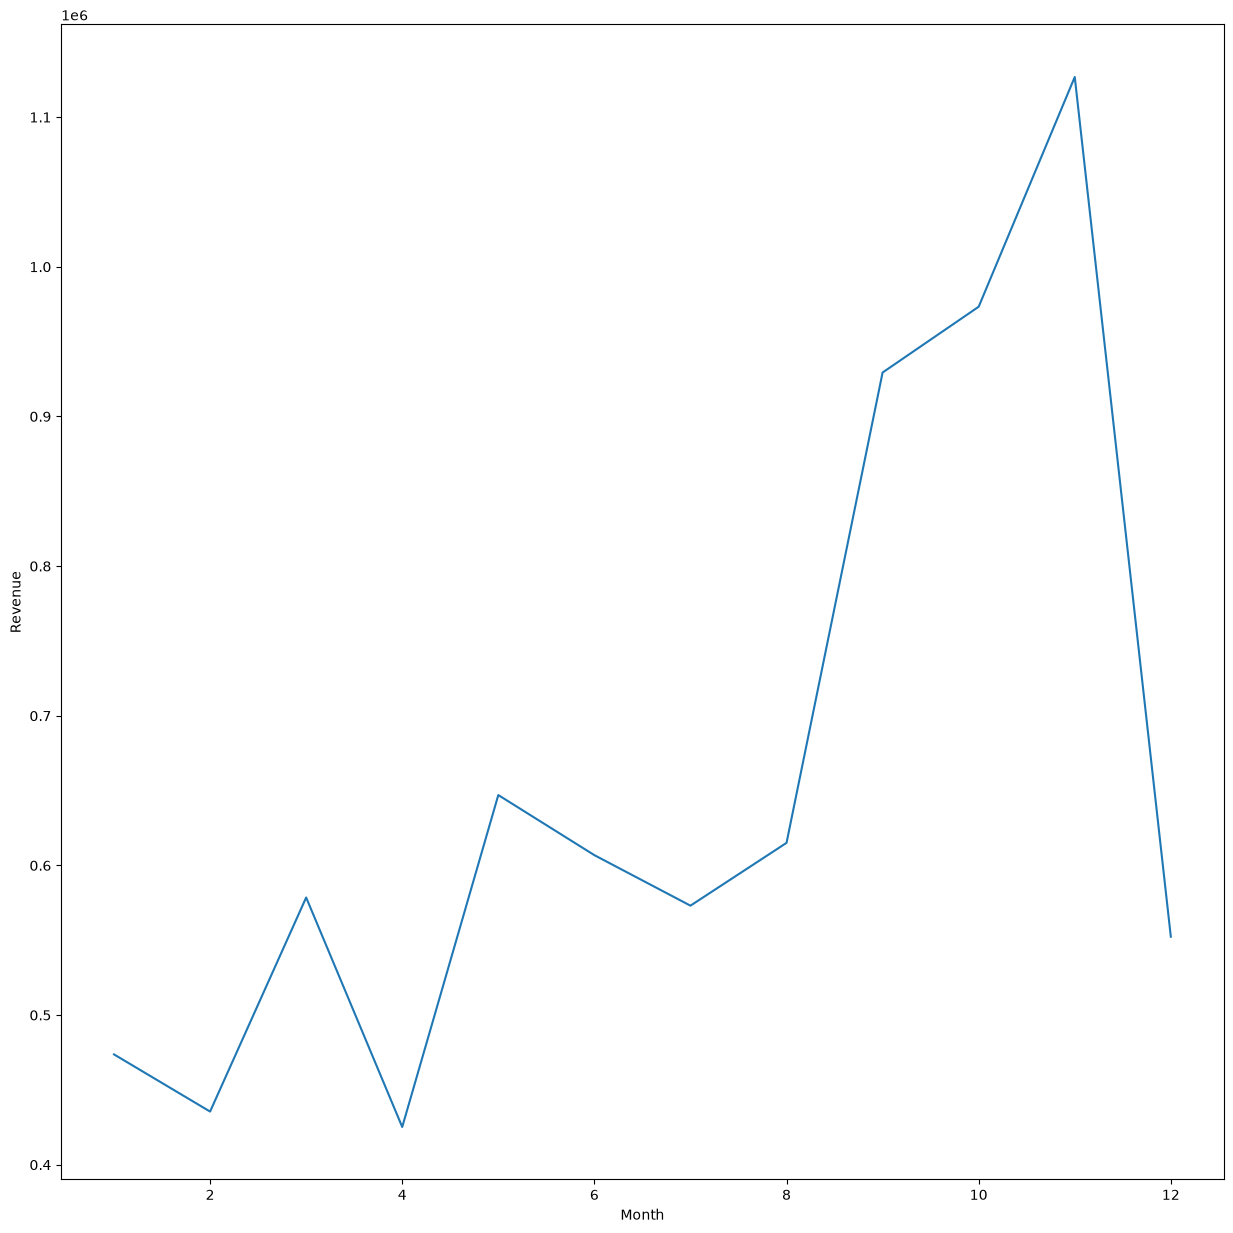

In [55]:
plt.figure(figsize=(15,15))
# plt.suptitle("Number of orders trend")
sns.lineplot(x=revenue_per_month["Month"],y=revenue_per_month["Revenue"])
plt.show()


In [56]:
#Customers by month
customers_per_month=df_copy.groupby(['Month'])['CustomerID'].nunique().reset_index()
customers_per_month['MoM%']=customers_per_month['CustomerID'].pct_change()*100
customers_per_month



,Month,CustomerID,MoM%
0,1,783,NaN
1,2,798,1.915709
2,3,1020,27.819549
3,4,899,-11.862745
4,5,1079,20.022247
5,6,1051,-2.594995
6,7,993,-5.518554
7,8,980,-1.309164
8,9,1302,32.857143
9,10,1425,9.447005


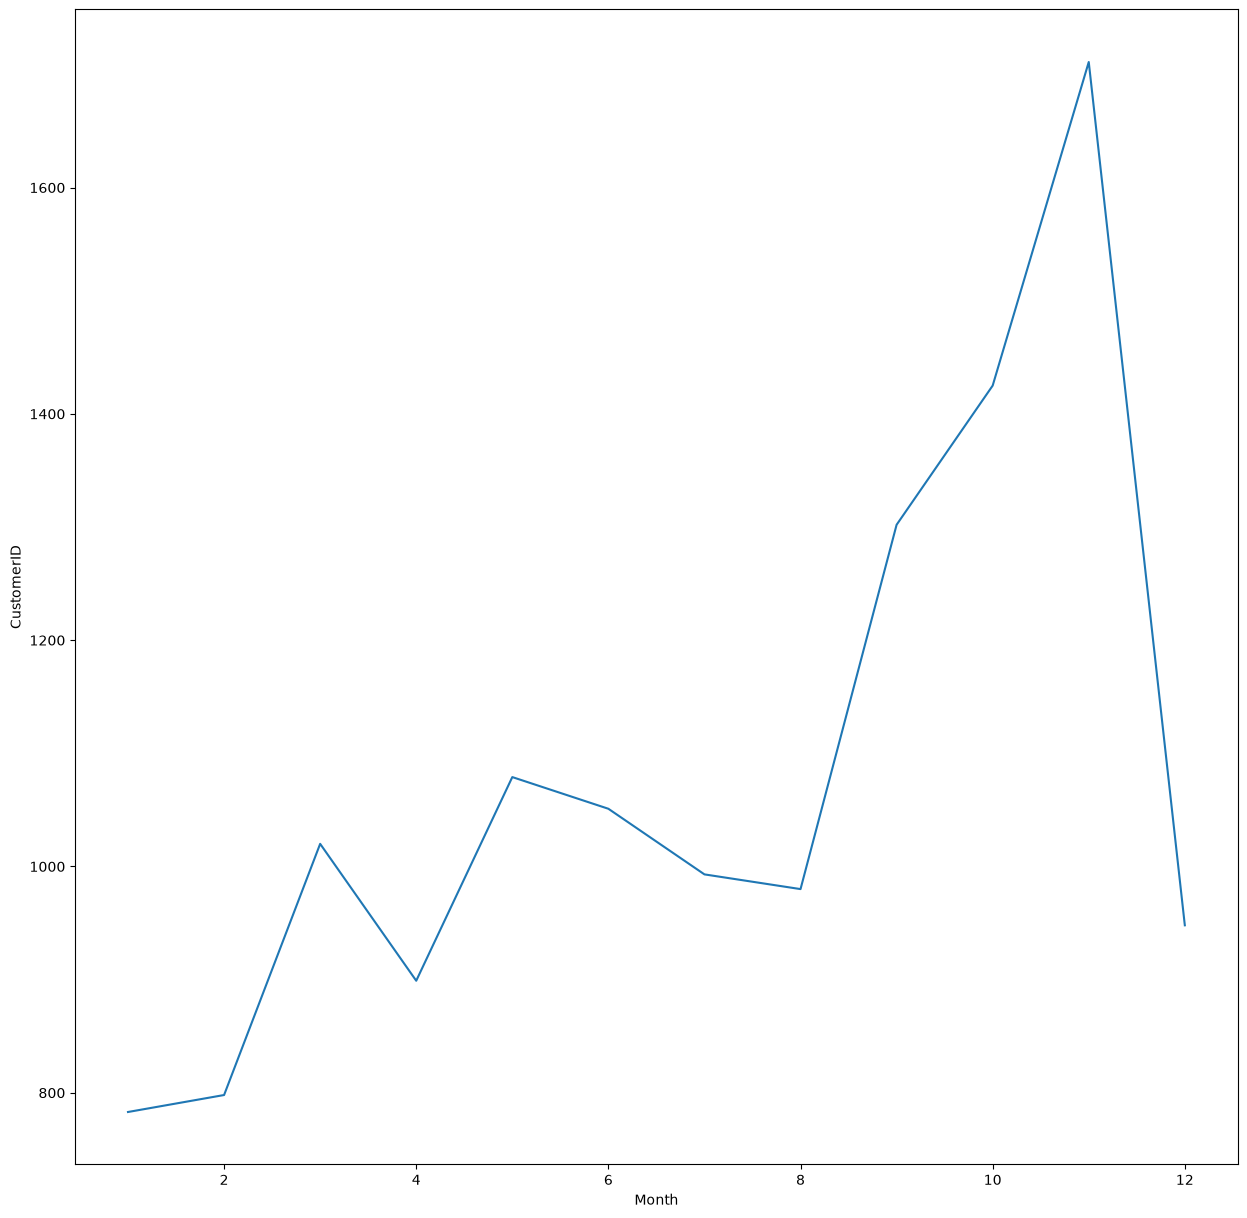

In [57]:
plt.figure(figsize=(15,15))
# plt.suptitle("Number of orders trend")
sns.lineplot(x=customers_per_month["Month"],y=customers_per_month["CustomerID"])
plt.show()


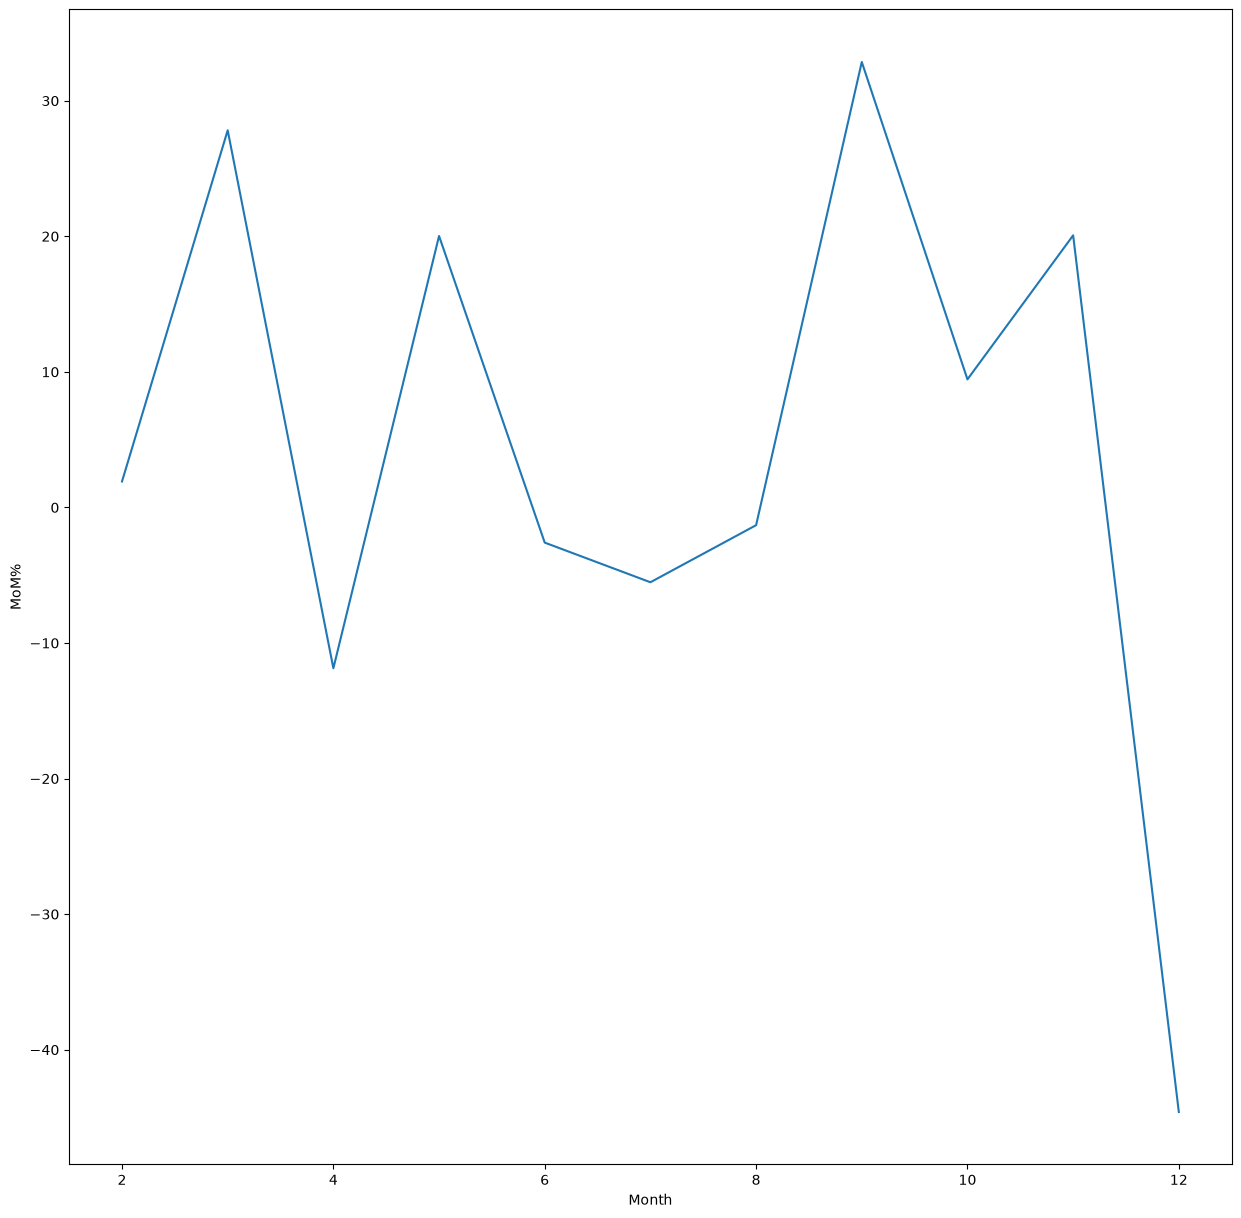

In [58]:
plt.figure(figsize=(15,15))
# plt.suptitle("Number of orders trend")
sns.lineplot(x=customers_per_month["Month"],y=customers_per_month["MoM%"])
plt.show()


In [59]:
#AOV by month
AOV_per_month=revenue_per_month["Revenue"]/orders_per_month["InvoiceNo"]
AOV_per_month.index=range(1,len(AOV_per_month)+1)
AOV_per_month



1     383.278236
2     362.341156
3     357.366405
4     307.241814
5     349.925187
6     355.514071
7     359.769191
8     398.366639
9     447.235915
10    430.095616
11    365.137741
12    323.403314
dtype: float64

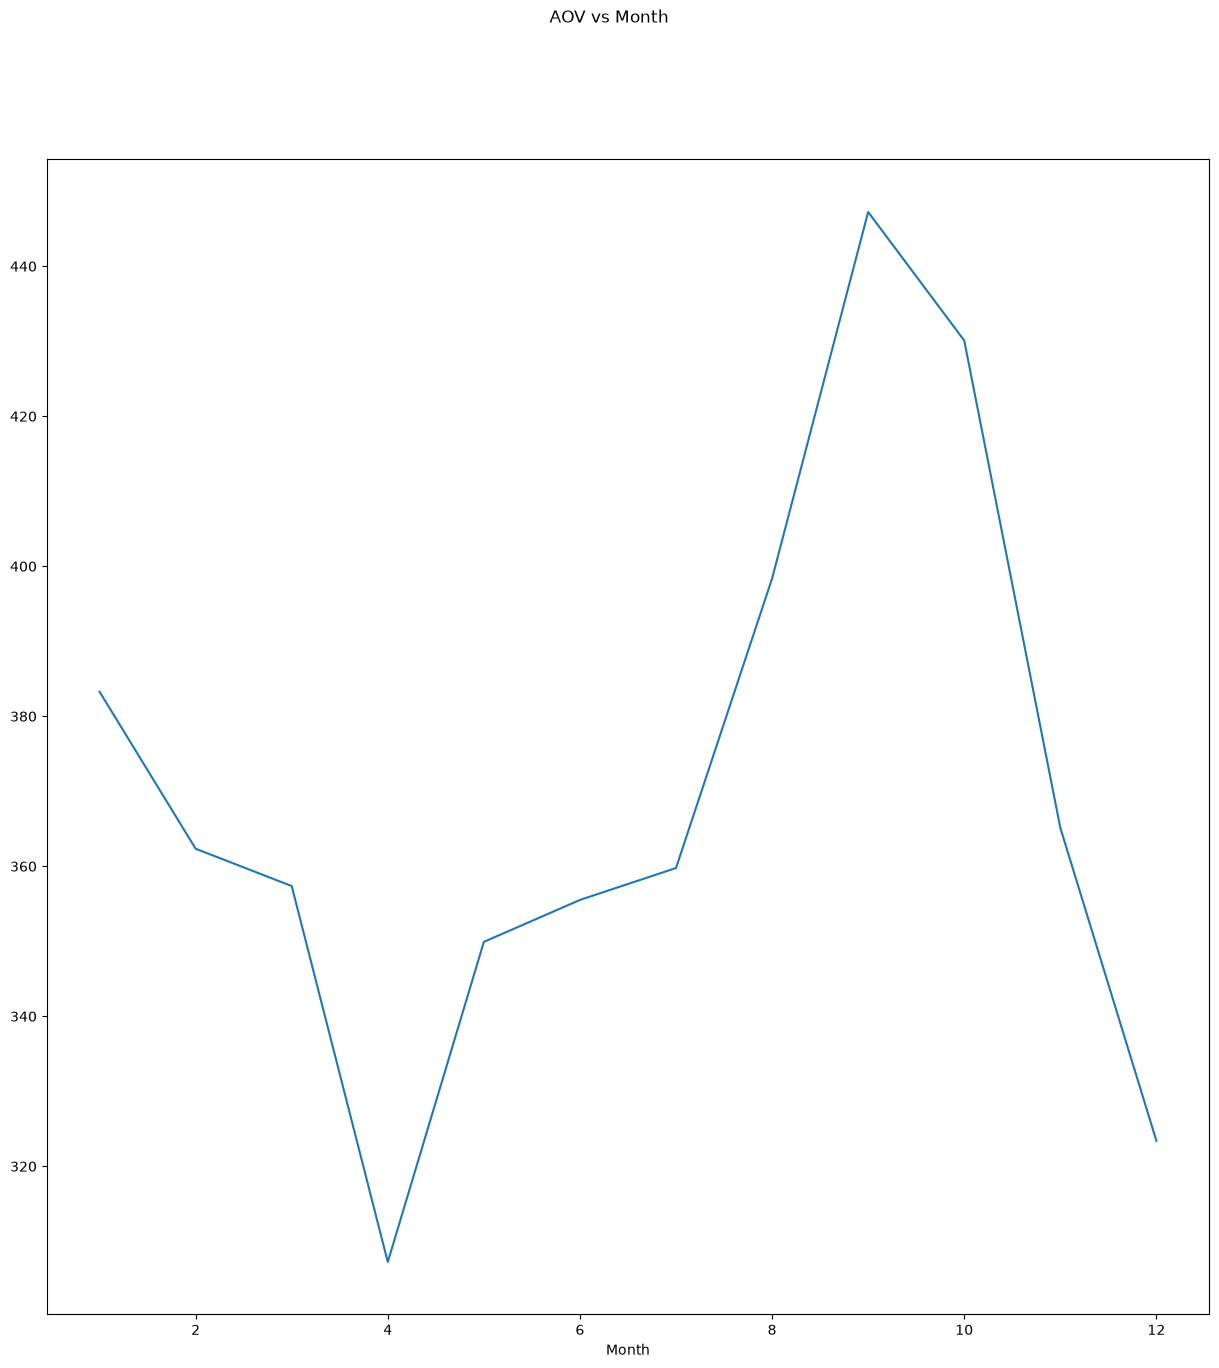

In [60]:
plt.figure(figsize=(15,15))
plt.suptitle("AOV vs Month")
sns.lineplot(x=AOV_per_month.index,y=AOV_per_month.values)
plt.xlabel('Month')
plt.show()

In [61]:
df_copy['InvoiceDate'].describe()

count                        384222
mean     2011-07-03 19:21:33.944750
min             2010-12-01 08:26:00
25%             2011-04-01 11:34:00
50%             2011-07-20 12:58:00
75%             2011-10-12 09:37:15
max             2011-11-30 17:42:00
Name: InvoiceDate, dtype: object

Observation: 

1)There is a sharp decline from january to april but after there is an increase in sales after april.

2) The most amount of customers are being observed during the month of decemeber.

3) The peak number of orders came at the month of november.

4) The highest AOV can be seen in the month of october 

5) With the amount of customers increasing , the orders also increase and hence sales also increases but there are cases where customers can make bulk amount of order which can affect the graph

New vs Returning Customers

In [62]:
df_copy=df[df['InvoiceDate']<'2011-12-01']

df_copy.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID,Revenue,Month,Year
count,384222.000000,384222,384222.000000,384222.000000,384222.000000,384222.000000,384222.000000
mean,12.205545,2011-07-03 19:21:33.944750,3.502443,15280.382492,20.657276,7.396146,2010.931409
min,-74215.000000,2010-12-01 08:26:00,0.000000,12346.000000,-77183.600000,1.000000,2010.000000
25%,2.000000,2011-04-01 11:34:00,1.250000,13932.000000,4.250000,5.000000,2011.000000
50%,5.000000,2011-07-20 12:58:00,1.950000,15150.000000,11.700000,8.000000,2011.000000
75%,12.000000,2011-10-12 09:37:15,3.750000,16779.000000,19.800000,10.000000,2011.000000
max,74215.000000,2011-11-30 17:42:00,38970.000000,18287.000000,77183.600000,12.000000,2011.000000
std,176.786144,NaN,71.249977,1713.388437,213.457124,3.360052,0.252757


In [63]:
# New vs returning customers
# A customer is "New" in the month of their first purchase and "Returning"
# in subsequent months. We compare months, not exact transaction dates.
df_copy['FirstPurchase'] = df_copy.groupby('CustomerID')['InvoiceDate'].transform('min')
df_copy['FirstPurchaseMonth'] = df_copy['FirstPurchase'].dt.to_period('M')
df_copy['MonthYear'] = df_copy['InvoiceDate'].dt.to_period('M')

df_copy['CustomerType'] = np.where(
    df_copy['FirstPurchaseMonth'] == df_copy['MonthYear'],
    'New',
    'Returning'
)
df_copy[['CustomerID','InvoiceDate','FirstPurchase','MonthYear','CustomerType']].head()

,CustomerID,InvoiceDate,FirstPurchase,MonthYear,CustomerType
0,17850.0,2010-12-01 08:26:00,2010-12-01 08:26:00,2010-12,New
1,17850.0,2010-12-01 08:26:00,2010-12-01 08:26:00,2010-12,New
2,17850.0,2010-12-01 08:26:00,2010-12-01 08:26:00,2010-12,New
3,17850.0,2010-12-01 08:26:00,2010-12-01 08:26:00,2010-12,New
4,17850.0,2010-12-01 08:26:00,2010-12-01 08:26:00,2010-12,New


In [64]:
df_copy.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Month,Year,FirstPurchase,FirstPurchaseMonth,MonthYear,CustomerType
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,12,2010,2010-12-01 08:26:00,2010-12,2010-12,New
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,2010,2010-12-01 08:26:00,2010-12,2010-12,New
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,12,2010,2010-12-01 08:26:00,2010-12,2010-12,New
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,2010,2010-12-01 08:26:00,2010-12,2010-12,New
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,2010,2010-12-01 08:26:00,2010-12,2010-12,New


In [65]:
# Monthly new vs returning customers
monthly_customer_type = (
    df_copy.groupby(['MonthYear', 'CustomerType'])['CustomerID']
    .nunique()
    .unstack(fill_value=0)
    .sort_index()
)
monthly_customer_type

CustomerType,New,Returning
MonthYear,,
2010-12,948,0
2011-01,421,362
2011-02,380,418
2011-03,440,580
2011-04,299,600
2011-05,279,800
2011-06,235,816
2011-07,191,802
2011-08,167,813


In [66]:
# Split transaction rows for revenue analysis
new_customer_rows = df_copy[df_copy['CustomerType'] == 'New']
returning_customer_rows = df_copy[df_copy['CustomerType'] == 'Returning']

new_customers_revenue = new_customer_rows['Revenue'].sum()
returning_customers_revenue = returning_customer_rows['Revenue'].sum()

print("Revenue from new-customer months:", new_customers_revenue)
print("Revenue from returning-customer months:", returning_customers_revenue)

Revenue from new-customer months: 2003449.813
Revenue from returning-customer months: 5933530.181


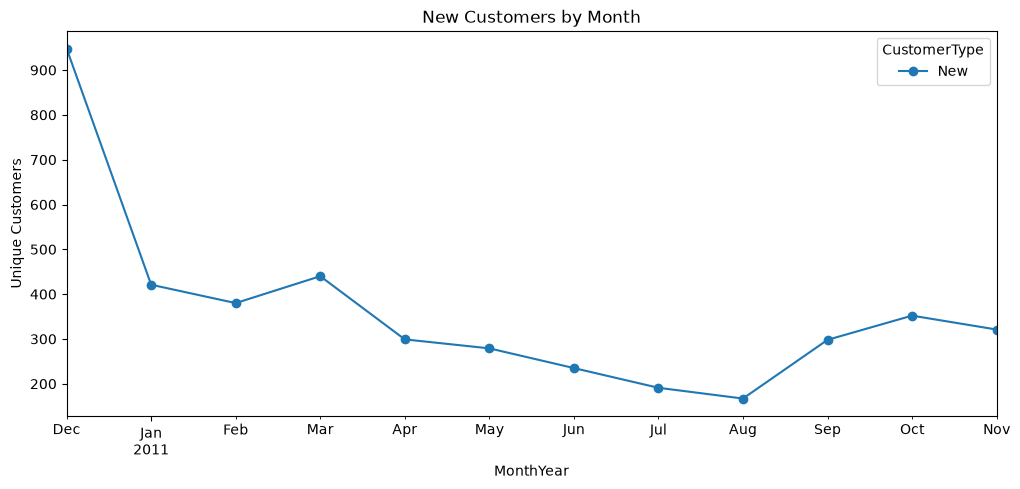

In [67]:
# Plot monthly new customers
monthly_customer_type[['New']].plot(figsize=(12,5), marker='o', title='New Customers by Month')
plt.ylabel('Unique Customers')
plt.show()

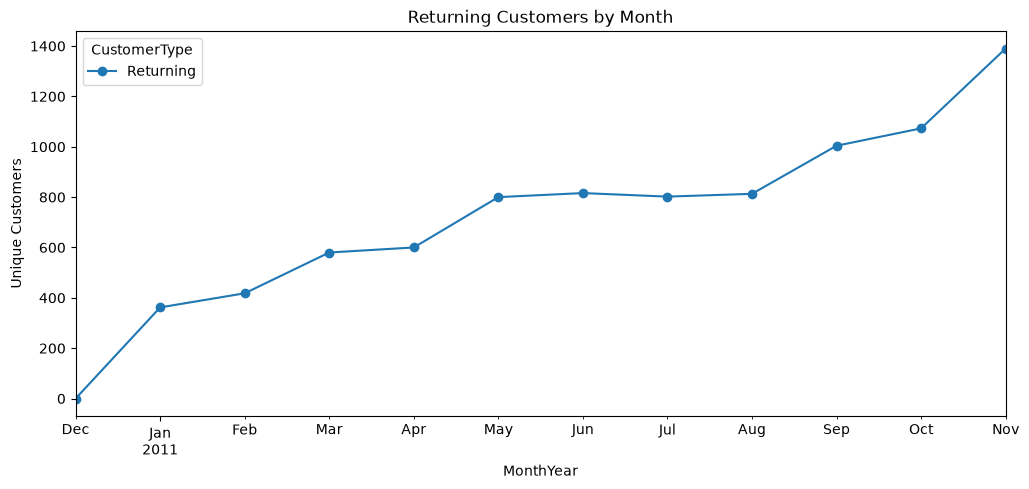

In [68]:
# Plot monthly returning customers
monthly_customer_type[['Returning']].plot(figsize=(12,5), marker='o', title='Returning Customers by Month')
plt.ylabel('Unique Customers')
plt.show()

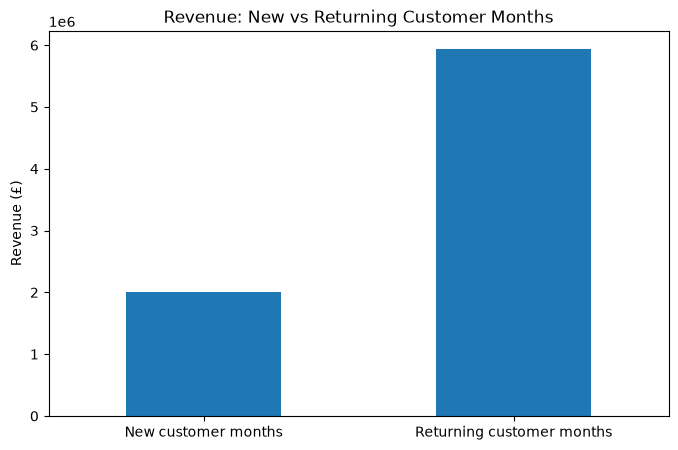

In [69]:
# Acquisition vs retention revenue
revenue_mix = pd.Series({
    'New customer months': new_customers_revenue,
    'Returning customer months': returning_customers_revenue
})
revenue_mix.plot(kind='bar', figsize=(8,5), title='Revenue: New vs Returning Customer Months')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=0)
plt.show()

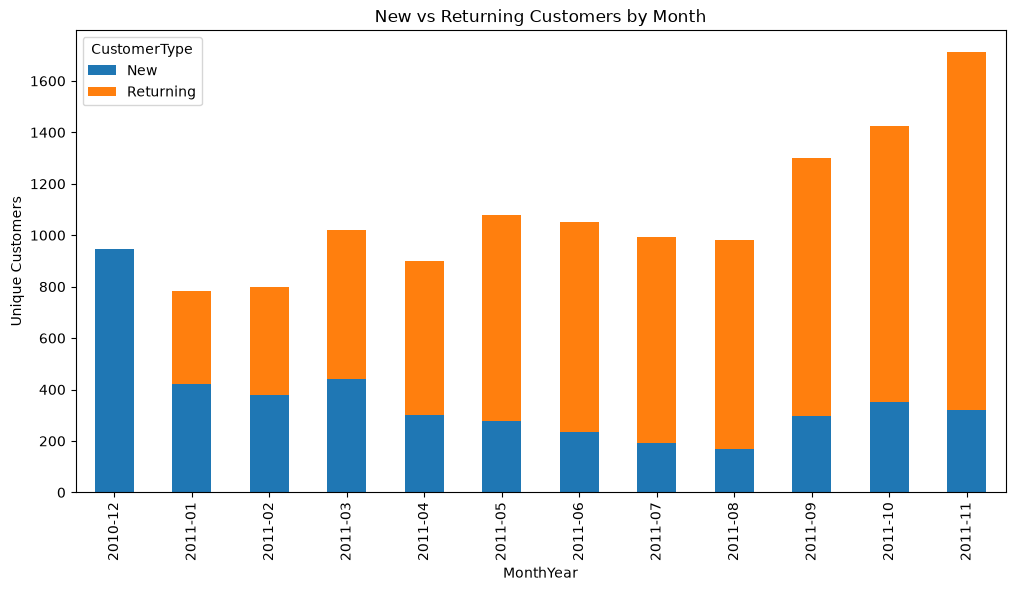

In [ ]:
# Monthly acquisition vs retention
new_return_monthly = monthly_customer_type.reindex(columns=['New','Returning'], fill_value=0)
new_return_monthly.plot(kind='bar', stacked=True, figsize=(12,6), title='New vs Returning Customers by Month')
plt.ylabel('Unique Customers')
plt.show()

<Axes: xlabel='MonthYear'>

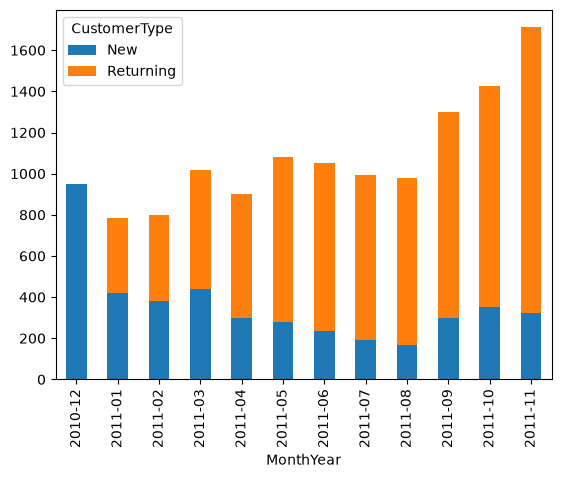

In [71]:
new_return_monthly.plot(kind='bar',stacked=True)

#Customer Behavior

In [72]:
df_copy.info()

<class 'pandas.DataFrame'>
Index: 384222 entries, 0 to 516383
Data columns (total 15 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   InvoiceNo           384222 non-null  object        
 1   StockCode           384222 non-null  object        
 2   Description         384222 non-null  object        
 3   Quantity            384222 non-null  int64         
 4   InvoiceDate         384222 non-null  datetime64[us]
 5   UnitPrice           384222 non-null  float64       
 6   CustomerID          384222 non-null  float64       
 7   Country             384222 non-null  str           
 8   Revenue             384222 non-null  float64       
 9   Month               384222 non-null  int32         
 10  Year                384222 non-null  int32         
 11  FirstPurchase       384222 non-null  datetime64[us]
 12  FirstPurchaseMonth  384222 non-null  period[M]     
 13  MonthYear           384222 non-null  period[M

In [73]:
#Number of orders per customer
orders_per_customers=df_copy.groupby(['CustomerID'])['InvoiceNo'].nunique()


In [74]:
#Amount spent by customer
revenue_per_customers=df_copy.groupby(['CustomerID'])['Revenue'].sum()

In [75]:
customer_behavior=pd.concat([orders_per_customers.rename("No of Orders"),revenue_per_customers.rename("Spent")],axis=1)
customer_behavior["AOV"]=customer_behavior['Spent']/customer_behavior['No of Orders']
customer_behavior["Units"]=df_copy.groupby(['CustomerID'])['Quantity'].sum()
customer_behavior.reset_index(inplace=True)
customer_behavior

,CustomerID,No of Orders,Spent,AOV,Units
0,12346.0,2,0.00,0.000000,0
1,12347.0,6,4085.18,680.863333,2266
2,12348.0,4,1797.24,449.310000,2341
3,12349.0,1,1757.55,1757.550000,631
4,12350.0,1,334.40,334.400000,197
...,...,...,...,...,...
4326,18280.0,1,180.60,180.600000,45
4327,18281.0,1,80.82,80.820000,54
4328,18282.0,2,98.76,49.380000,70
4329,18283.0,15,1837.53,122.502000,1215


In [76]:
#TOP Customers by Spending 
top_revenue=customer_behavior.sort_values('Spent',ascending=False).head(10)
top_revenue


,CustomerID,No of Orders,Spent,AOV,Units
1685,14646.0,74,267761.00,3618.391892,188761
4193,18102.0,59,244952.95,4151.744915,61424
3722,17450.0,54,185759.77,3439.995741,68289
1876,14911.0,238,125482.36,527.236807,73210
54,12415.0,26,123725.45,4758.671154,77242
1331,14156.0,66,113214.59,1715.372576,56908
3765,17511.0,44,80746.06,1835.137727,55797
3169,16684.0,30,60490.10,2016.336667,44658
993,13694.0,57,59559.38,1044.901404,59459
2171,15311.0,113,58218.04,515.203894,37175


In [77]:
#TOP Customers by No. of Orders 
top_orders=customer_behavior.sort_values('No of Orders',ascending=False).head(10)
top_orders


,CustomerID,No of Orders,Spent,AOV,Units
1876,14911.0,238,125482.36,527.236807,73210
323,12748.0,215,27406.56,127.472372,23091
4006,17841.0,165,37338.16,226.291879,21070
1656,14606.0,126,11291.51,89.615159,5773
560,13089.0,114,52640.51,461.758860,28454
2171,15311.0,113,58218.04,515.203894,37175
480,12971.0,87,10768.36,123.774253,9147
1599,14527.0,83,7106.42,85.619518,1926
793,13408.0,77,26097.54,338.929091,15167
2693,16029.0,76,53168.69,699.588026,33632


In [78]:
customer_behavior.describe()

,CustomerID,No of Orders,Spent,AOV,Units
count,4331.000000,4331.000000,4331.000000,4331.000000,4331.000000
mean,15301.893789,4.910875,1832.597551,315.267730,1082.807435
std,1721.496466,9.025901,7944.283177,354.923780,4514.711080
min,12346.000000,1.000000,-4287.630000,-4287.630000,-303.000000
25%,13815.500000,1.000000,288.755000,151.646667,149.000000
50%,15301.000000,3.000000,628.780000,237.900000,356.000000
75%,16780.500000,5.000000,1545.905000,371.640000,922.500000
max,18287.000000,238.000000,267761.000000,6207.670000,188761.000000


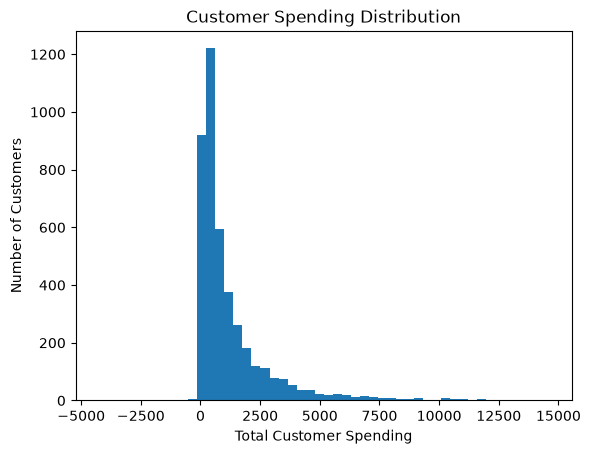

In [79]:
# Analyze spending and order-frequency distributions.
spentding=customer_behavior[customer_behavior['Spent']<15450.905000]
plt.hist(spentding['Spent'],bins=50)
plt.xlabel('Total Customer Spending')
plt.ylabel('Number of Customers')
plt.title('Customer Spending Distribution')
plt.show()

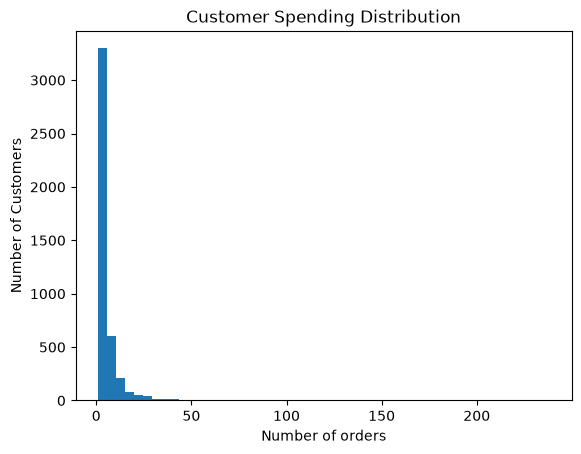

In [80]:
ordering=customer_behavior[customer_behavior['No of Orders']<150]

plt.hist(customer_behavior['No of Orders'],bins=50)
plt.xlabel('Number of orders')
plt.ylabel('Number of Customers')
plt.title('Customer Spending Distribution')
plt.show()

In [81]:
#Frequency
customer_behavior=pd.concat([customer_behavior,df.groupby(['CustomerID']).size().reset_index(name='Frequency')],axis=1)
customer_behavior

,CustomerID,No of Orders,Spent,AOV,Units,CustomerID,Frequency
0,12346.0,2.0,0.00,0.000000,0.0,12346.0,2
1,12347.0,6.0,4085.18,680.863333,2266.0,12347.0,182
2,12348.0,4.0,1797.24,449.310000,2341.0,12348.0,31
3,12349.0,1.0,1757.55,1757.550000,631.0,12349.0,73
4,12350.0,1.0,334.40,334.400000,197.0,12350.0,17
...,...,...,...,...,...,...,...
4367,NaN,NaN,NaN,NaN,NaN,18280.0,10
4368,NaN,NaN,NaN,NaN,NaN,18281.0,7
4369,NaN,NaN,NaN,NaN,NaN,18282.0,13
4370,NaN,NaN,NaN,NaN,NaN,18283.0,721


In [82]:
# Recency: days since each customer's most recent purchase
reference_date = df_copy['InvoiceDate'].max() + pd.Timedelta(days=1)
reference_date

Timestamp('2011-12-01 17:42:00')

In [83]:
df_copy.info()

<class 'pandas.DataFrame'>
Index: 384222 entries, 0 to 516383
Data columns (total 15 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   InvoiceNo           384222 non-null  object        
 1   StockCode           384222 non-null  object        
 2   Description         384222 non-null  object        
 3   Quantity            384222 non-null  int64         
 4   InvoiceDate         384222 non-null  datetime64[us]
 5   UnitPrice           384222 non-null  float64       
 6   CustomerID          384222 non-null  float64       
 7   Country             384222 non-null  str           
 8   Revenue             384222 non-null  float64       
 9   Month               384222 non-null  int32         
 10  Year                384222 non-null  int32         
 11  FirstPurchase       384222 non-null  datetime64[us]
 12  FirstPurchaseMonth  384222 non-null  period[M]     
 13  MonthYear           384222 non-null  period[M

In [84]:
last_purchase=df_copy.groupby(['CustomerID'])['InvoiceDate'].max()
Recency=(reference_date-last_purchase).dt.days
Recency

CustomerID
12346.0    317
12347.0     31
12348.0     67
12349.0     10
12350.0    302
          ... 
18280.0    269
18281.0    172
18282.0    114
18283.0      1
18287.0     34
Name: InvoiceDate, Length: 4331, dtype: int64

In [85]:
#Frequency
Frequency=df_copy.groupby(['CustomerID'])['InvoiceNo'].nunique()
Frequency

CustomerID
12346.0     2
12347.0     6
12348.0     4
12349.0     1
12350.0     1
           ..
18280.0     1
18281.0     1
18282.0     2
18283.0    15
18287.0     3
Name: InvoiceNo, Length: 4331, dtype: int64

In [86]:
#Monetary
Monetary=df_copy.groupby(['CustomerID'])['Revenue'].sum()
Monetary


CustomerID
12346.0       0.00
12347.0    4085.18
12348.0    1797.24
12349.0    1757.55
12350.0     334.40
            ...   
18280.0     180.60
18281.0      80.82
18282.0      98.76
18283.0    1837.53
18287.0    1837.28
Name: Revenue, Length: 4331, dtype: float64

In [87]:
# RFM table
rfm = pd.concat([
    Recency.rename('Recency'),
    Frequency.rename('Frequency'),
    Monetary.rename('Monetary')
], axis=1).reset_index()

rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346.0,317,2,0.00
1,12347.0,31,6,4085.18
2,12348.0,67,4,1797.24
3,12349.0,10,1,1757.55
4,12350.0,302,1,334.40


In [88]:
# Quartile-based RFM scoring
# Recency: lower is better, so labels are reversed.
# Frequency and Monetary: higher is better.
rfm['R_score'] = pd.qcut(rfm['Recency'], 4, labels=[4,3,2,1], duplicates='drop')
rfm['F_score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 4, labels=[1,2,3,4], duplicates='drop')
rfm['M_score'] = pd.qcut(rfm['Monetary'].rank(method='first'), 4, labels=[1,2,3,4], duplicates='drop')
rfm[['R_score','F_score','M_score']] = rfm[['R_score','F_score','M_score']].astype(int)
rfm['RFM_Score'] = rfm['R_score'] + rfm['F_score'] + rfm['M_score']
rfm['RFM_Segment'] = np.select(
    [
        rfm['RFM_Score'] >= 10,
        (rfm['RFM_Score'] >= 8) & (rfm['RFM_Score'] < 10),
        (rfm['RFM_Score'] >= 6) & (rfm['RFM_Score'] < 8),
        rfm['RFM_Score'] < 6
    ],
    ['High Value','Loyal / Active','Needs Attention','At Risk'],
    default='Unclassified'
)
rfm.head()

,CustomerID,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_Score,RFM_Segment
0,12346.0,317,2,0.00,1,2,1,4,At Risk
1,12347.0,31,6,4085.18,3,4,4,11,High Value
2,12348.0,67,4,1797.24,2,3,4,9,Loyal / Active
3,12349.0,10,1,1757.55,4,1,4,9,Loyal / Active
4,12350.0,302,1,334.40,1,1,2,4,At Risk


 8 — Product Analysis

In [89]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Month,Year
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,12,2010
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,2010
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,12,2010
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,2010
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,2010


In [90]:
df['StockCode'].nunique()

3684

In [91]:
df['Description'].nunique()


3896

In [92]:
# Product-level performance for the complete 12-month analysis window
# Separate operational/non-product transaction codes from normal merchandise.
special_codes = {
    'POST','DOT','M','BANK CHARGES','AMAZONFEE','ADJUST',
    'D','CRUK','C2','S','PADS','B','MIA','gift_0001','gift_0002',
    'gift_0003','gift_0004'
}

product_df = df_copy[~df_copy['StockCode'].astype(str).isin(special_codes)].copy()

product_details = (
    product_df.groupby(['StockCode','Description'])
    .agg(
        Revenue=('Revenue','sum'),
        Units=('Quantity','sum'),
        Orders=('InvoiceNo','nunique')
    )
    .reset_index()
)
product_details.head()

,StockCode,Description,Revenue,Units,Orders
0,10002,INFLATABLE POLITICAL GLOBE,699.55,823,49
1,10080,GROOVY CACTUS INFLATABLE,114.41,291,21
2,10120,DOGGY RUBBER,39.06,186,28
3,10125,MINI FUNKY DESIGN TAPES,907.35,1199,59
4,10133,COLOURING PENCILS BROWN TUBE,1134.79,2363,123


In [93]:
# Top products by revenue
top_products_revenue = product_details.sort_values('Revenue', ascending=False).head(10)
top_products_revenue

,StockCode,Description,Revenue,Units,Orders
1249,22423,REGENCY CAKESTAND 3 TIER,128139.37,11147,1833
3590,85123A,WHITE HANGING HEART T-LIGHT HOLDER,91774.96,33384,1961
3584,85099B,JUMBO BAG RED RETROSPOT,81067.32,43923,1598
2612,47566,PARTY BUNTING,67163.13,14921,1381
2817,84879,ASSORTED COLOUR BIRD ORNAMENT,54332.45,33941,1343
1937,23084,RABBIT NIGHT LIGHT,44192.65,23374,702
2679,79321,CHILLI LIGHTS,43804.74,9147,505
1324,22502,PICNIC BASKET WICKER 60 PIECES,39619.50,61,2
932,22086,PAPER CHAIN KIT 50'S CHRISTMAS,37570.26,13746,891
1216,22386,JUMBO BAG PINK POLKADOT,35635.36,19263,869


In [94]:
# Top products by net units
top_products_units = product_details.sort_values('Units', ascending=False).head(10)
top_products_units

,StockCode,Description,Revenue,Units,Orders
2711,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,12927.84,51756,456
3584,85099B,JUMBO BAG RED RETROSPOT,81067.32,43923,1598
2817,84879,ASSORTED COLOUR BIRD ORNAMENT,54332.45,33941,1343
3590,85123A,WHITE HANGING HEART T-LIGHT HOLDER,91774.96,33384,1961
361,21212,PACK OF 72 RETROSPOT CAKE CASES,16074.20,33102,1021
1314,22492,MINI PAINT SET VINTAGE,15719.75,25589,328
1039,22197,POPCORN HOLDER,19109.84,25149,616
1436,22616,PACK OF 12 LONDON TISSUES,7043.22,24688,369
857,21977,PACK OF 60 PINK PAISLEY CAKE CASES,11435.25,23913,655
1937,23084,RABBIT NIGHT LIGHT,44192.65,23374,702


In [95]:
# Lowest-revenue normal products
# These are merchandise products only; operational charges/codes were separated above.
weak_products = product_details.sort_values('Revenue').head(10)
weak_products

,StockCode,Description,Revenue,Units,Orders
1586,22769,CHALKBOARD KITCHEN ORGANISER,-87.80,-4,5
3296,79323W,WHITE CHERRY LIGHTS,-54.00,-8,1
2866,85063,CREAM SWEETHEART MAGAZINE RACK,-46.85,-3,2
2535,35400,WOODEN BOX ADVENT CALENDAR,-45.70,-6,13
629,21645,ASSORTED TUTTI FRUTTI ROUND BOX,-39.60,-24,1
3295,79323P,PINK CHERRY LIGHTS,-27.00,-4,3
88,20703,BLUE PADDED SOFT MOBILE,-25.50,-6,4
2857,85042,ANTIQUE LILY FAIRY LIGHTS,-14.85,-3,2
2868,85065,CREAM SWEETHEART TRAYS,-12.75,-1,1
2591,37503,TEA TIME CAKE STAND IN GIFT BOX,-10.75,-1,1


In [96]:
# High-volume / low-revenue products
unit_75 = product_details['Units'].quantile(0.75)
revenue_25 = product_details['Revenue'].quantile(0.25)
high_volume_low_revenue = product_details[
    (product_details['Units'] >= unit_75) &
    (product_details['Revenue'] <= revenue_25)
].sort_values(['Units','Revenue'], ascending=[False, True])
high_volume_low_revenue.head(15)

,StockCode,Description,Revenue,Units,Orders


In [97]:
# Low-volume / high-revenue products
unit_25 = product_details['Units'].quantile(0.25)
revenue_75 = product_details['Revenue'].quantile(0.75)
low_volume_high_revenue = product_details[
    (product_details['Units'] <= unit_25) &
    (product_details['Revenue'] >= revenue_75)
].sort_values('Revenue', ascending=False)
low_volume_high_revenue.head(15)

,StockCode,Description,Revenue,Units,Orders
2722,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,15495.59,-2200,274
1649,22827,RUSTIC SEVENTEEN DRAWER SIDEBOARD,5000.00,32,29
1476,22656,VINTAGE BLUE KITCHEN CABINET,2885.00,20,26
1645,22823,CHEST NATURAL WOOD 20 DRAWERS,2745.00,24,13


#  Geographic Analysis
Goal: understand where revenue and customers are concentrated, and identify markets with different customer economics.

In [98]:
# Country-level performance
country_analysis = (
    df_copy.groupby('Country')
    .agg(
        Revenue=('Revenue','sum'),
        Orders=('InvoiceNo','nunique'),
        Customers=('CustomerID','nunique'),
        Units=('Quantity','sum')
    )
    .reset_index()
)
country_analysis['AOV'] = country_analysis['Revenue'] / country_analysis['Orders']
country_analysis['Revenue_per_Customer'] = country_analysis['Revenue'] / country_analysis['Customers']
country_analysis = country_analysis.sort_values('Revenue', ascending=False)
country_analysis.head(15)

,Country,Revenue,Orders,Customers,Units,AOV,Revenue_per_Customer
35,United Kingdom,6450202.634,19027,3916,3817910,339.002609,1647.140611
23,Netherlands,272933.520,98,9,192170,2785.035918,30325.946667
10,EIRE,243025.410,309,3,132242,786.490000,81008.470000
14,Germany,213704.770,581,94,113408,367.822324,2273.455000
13,France,189577.220,437,86,106175,433.815149,2204.386279
0,Australia,137009.770,69,9,83643,1985.648841,15223.307778
32,Switzerland,55739.400,71,21,29778,785.061972,2654.257143
30,Spain,54484.600,102,30,26561,534.162745,1816.153333
3,Belgium,39501.530,114,25,22055,346.504649,1580.061200
31,Sweden,36585.410,44,8,35632,831.486591,4573.176250


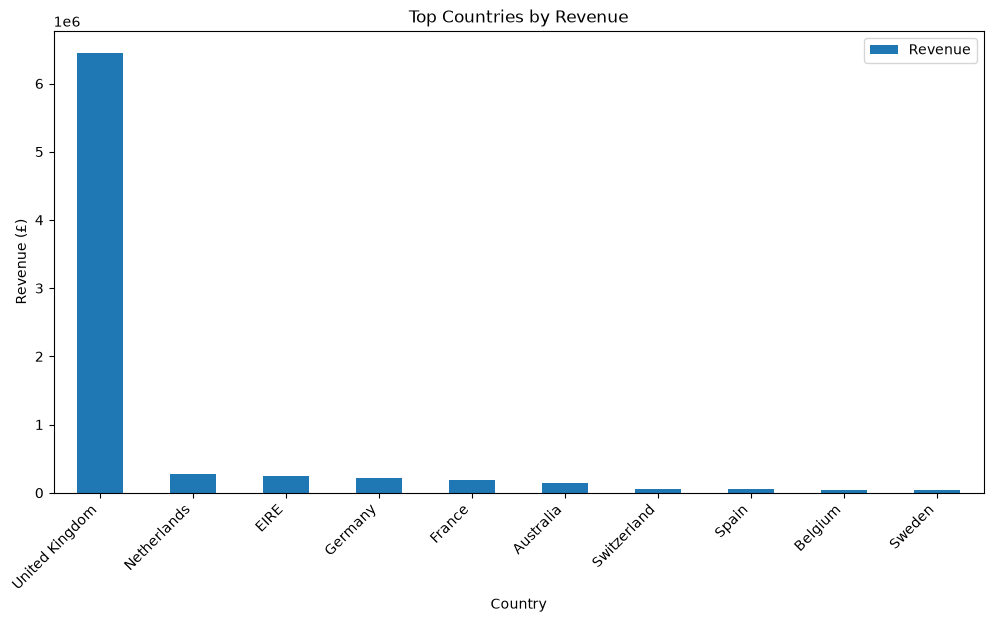

In [99]:
# Top countries by revenue
country_analysis.head(10).plot(
    x='Country', y='Revenue', kind='bar', figsize=(12,6),
    title='Top Countries by Revenue'
)
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45, ha='right')
plt.show()

In [100]:
# International markets excluding the UK
international = country_analysis[country_analysis['Country'] != 'United Kingdom'].copy()
international.sort_values('Revenue', ascending=False).head(10)

,Country,Revenue,Orders,Customers,Units,AOV,Revenue_per_Customer
23,Netherlands,272933.52,98,9,192170,2785.035918,30325.946667
10,EIRE,243025.41,309,3,132242,786.490000,81008.470000
14,Germany,213704.77,581,94,113408,367.822324,2273.455000
13,France,189577.22,437,86,106175,433.815149,2204.386279
0,Australia,137009.77,69,9,83643,1985.648841,15223.307778
32,Switzerland,55739.40,71,21,29778,785.061972,2654.257143
30,Spain,54484.60,102,30,26561,534.162745,1816.153333
3,Belgium,39501.53,114,25,22055,346.504649,1580.061200
31,Sweden,36585.41,44,8,35632,831.486591,4573.176250
19,Japan,35457.55,27,8,25267,1313.242593,4432.193750


###  9 observations
- The United Kingdom is expected to dominate the dataset because this is a UK-based retailer.
- International markets should be compared using both revenue and revenue per customer rather than revenue alone.
- A small market with high revenue per customer can represent a different commercial opportunity from a large, low-value market.

#  10 — Business Story / Executive Summary
Turn the analysis into a coherent story: performance → customer behavior → products → geography → implications.

In [101]:
# Core summary metrics for the executive story
summary_metrics = {
    'Revenue (£)': df_copy['Revenue'].sum(),
    'Orders': df_copy['InvoiceNo'].nunique(),
    'Customers': df_copy['CustomerID'].nunique(),
    'AOV (£)': df_copy['Revenue'].sum() / df_copy['InvoiceNo'].nunique(),
    'Revenue / Customer (£)': df_copy['Revenue'].sum() / df_copy['CustomerID'].nunique(),
    'Repeat Customer Rate (%)': (
        (df_copy.groupby('CustomerID')['InvoiceNo'].nunique() > 1).mean() * 100
    )
}
pd.Series(summary_metrics)

Revenue (£)                 7.936980e+06
Orders                      2.126900e+04
Customers                   4.331000e+03
AOV (£)                     3.731713e+02
Revenue / Customer (£)      1.832598e+03
Repeat Customer Rate (%)    6.869083e+01
dtype: float64

### Executive narrative
**1. Overall performance:** Revenue, orders, customer count and AOV establish the commercial baseline.

**2. Customer behavior:** The customer base is highly uneven, with a relatively small group contributing a large share of spending. RFM makes this concentration visible.

**3. Retention:** New and returning customers should be viewed separately. Returning-customer activity is important for sustaining revenue beyond acquisition.

**4. Products:** Product performance should be evaluated using revenue, net units and order reach, while operational transaction codes are kept separate from merchandise.

**5. Geography:** The UK is the core market, while international markets can be compared on customer value and order economics.

**6. Next step:** Convert customer-level RFM behavior into predictive features for churn/risk modeling.

#  11 — Recommendations
Recommendations below are directly tied to patterns measured in the analysis.

### Business recommendations
1. **Retention:** Prioritize customers with high monetary value but increasing recency; use targeted reactivation campaigns.
2. **Customer development:** Customers with moderate frequency and monetary value can be encouraged toward repeat purchasing through relevant cross-sell/upsell offers.
3. **High-value customers:** Protect the highest-value segment with personalized communication and early access to relevant products.
4. **Product portfolio:** Investigate high-volume/low-revenue products for pricing, discounting, bundling and margin implications.
5. **International growth:** Compare international countries on revenue per customer and AOV before allocating acquisition effort.
6. **Operational quality:** Keep cancellations/returns and non-product transaction codes visible in analytical QA, but do not interpret them as normal product performance.
7. **Predictive next step:** Build a temporal churn label and model customer churn probability using RFM and behavioral features.

#  12 — Feature Engineering
Create a customer-level modeling table. The target is deliberately defined using a future inactivity window to reduce leakage.

In [102]:
# Feature engineering cutoff
# Use the last 90 days of the complete 12-month window as the future-label period.
analysis_start = df_copy['InvoiceDate'].min()
analysis_end = df_copy['InvoiceDate'].max()
label_cutoff = analysis_end - pd.Timedelta(days=90)

feature_txn = df_copy[df_copy['InvoiceDate'] <= label_cutoff].copy()
future_txn = df_copy[df_copy['InvoiceDate'] > label_cutoff].copy()

feature_reference = feature_txn['InvoiceDate'].max() + pd.Timedelta(days=1)

customer_features = (
    feature_txn.groupby('CustomerID')
    .agg(
        Recency=('InvoiceDate', lambda x: (feature_reference - x.max()).days),
        Frequency=('InvoiceNo', 'nunique'),
        Monetary=('Revenue', 'sum'),
        AvgOrderValue=('Revenue', lambda x: x.sum() / feature_txn.loc[x.index, 'InvoiceNo'].nunique()),
        TotalUnits=('Quantity', 'sum'),
        ActiveDays=('InvoiceDate', lambda x: x.dt.date.nunique()),
        ProductVariety=('StockCode', 'nunique'),
        Country=('Country', 'first')
    )
    .reset_index()
)

# Future activity: churn = no purchase in the next 90 days.
future_orders = future_txn.groupby('CustomerID')['InvoiceNo'].nunique()
customer_features['FutureOrders'] = customer_features['CustomerID'].map(future_orders).fillna(0)
customer_features['Churn'] = (customer_features['FutureOrders'] == 0).astype(int)

customer_features.head()

,CustomerID,Recency,Frequency,Monetary,AvgOrderValue,TotalUnits,ActiveDays,ProductVariety,Country,FutureOrders,Churn
0,12346.0,227,2,0.00,0.000000,0,1,1,United Kingdom,0.0,1
1,12347.0,31,5,2790.86,558.172000,1590,5,82,Iceland,1.0,0
2,12348.0,150,3,1487.24,495.746667,2124,3,22,Finland,1.0,0
3,12350.0,212,1,334.40,334.400000,197,1,17,Norway,0.0,1
4,12352.0,164,8,601.18,75.147500,188,4,26,Norway,3.0,0


In [103]:
# Additional behavioral features
customer_features['OrdersPerActiveDay'] = (
    customer_features['Frequency'] / customer_features['ActiveDays'].replace(0, np.nan)
)
customer_features['RevenuePerUnit'] = (
    customer_features['Monetary'] / customer_features['TotalUnits'].replace(0, np.nan)
)
customer_features.isna().sum()

CustomerID            0
Recency               0
Frequency             0
Monetary              0
AvgOrderValue         0
TotalUnits            0
ActiveDays            0
ProductVariety        0
Country               0
FutureOrders          0
Churn                 0
OrdersPerActiveDay    0
RevenuePerUnit        5
dtype: int64

### Leakage check
The model features are calculated only from transactions available before `label_cutoff`. `FutureOrders` is used only to create the target and must NOT be included as a model feature.

#  13 — SQL Analysis
Use SQLite to reproduce important business questions in SQL. This demonstrates that the analytical logic is not tied only to pandas.

In [106]:
import sqlite3

sql_df = df_copy.copy()
sql_df['InvoiceDate'] = sql_df['InvoiceDate'].astype(str)

conn = sqlite3.connect(':memory:')
# print(sql_df.dtypes)
sql_df['FirstPurchaseMonth'] = sql_df['FirstPurchaseMonth'].astype(str)
sql_df['MonthYear'] = sql_df['MonthYear'].astype(str)
sql_df.to_sql('online_retail', conn, index=False, if_exists='replace')

sql_top_customers = pd.read_sql_query('''
SELECT CustomerID,
       SUM(Revenue) AS Revenue,
       COUNT(DISTINCT InvoiceNo) AS Orders
FROM online_retail
GROUP BY CustomerID
ORDER BY Revenue DESC
LIMIT 10;
''', conn)
sql_top_customers

,CustomerID,Revenue,Orders
0,14646.0,267761.00,74
1,18102.0,244952.95,59
2,17450.0,185759.77,54
3,14911.0,125482.36,238
4,12415.0,123725.45,26
5,14156.0,113214.59,66
6,17511.0,80746.06,44
7,16684.0,60490.10,30
8,13694.0,59559.38,57
9,15311.0,58218.04,113


In [107]:
# Monthly revenue in SQL
sql_monthly = pd.read_sql_query('''
SELECT substr(InvoiceDate, 1, 7) AS Month,
       SUM(Revenue) AS Revenue,
       COUNT(DISTINCT InvoiceNo) AS Orders,
       COUNT(DISTINCT CustomerID) AS Customers
FROM online_retail
GROUP BY substr(InvoiceDate, 1, 7)
ORDER BY Month;
''', conn)
sql_monthly

,Month,Revenue,Orders,Customers
0,2010-12,552372.860,1708,948
1,2011-01,473731.900,1236,783
2,2011-02,435534.070,1202,798
3,2011-03,578576.210,1619,1020
4,2011-04,425222.671,1384,899
5,2011-05,647011.670,1849,1079
6,2011-06,606862.520,1707,1051
7,2011-07,573112.321,1593,993
8,2011-08,615078.090,1544,980
9,2011-09,929356.232,2078,1302


In [108]:
# Country performance in SQL
sql_country = pd.read_sql_query('''
SELECT Country,
       SUM(Revenue) AS Revenue,
       COUNT(DISTINCT InvoiceNo) AS Orders,
       COUNT(DISTINCT CustomerID) AS Customers,
       SUM(Revenue) / COUNT(DISTINCT CustomerID) AS RevenuePerCustomer
FROM online_retail
GROUP BY Country
ORDER BY Revenue DESC;
''', conn)
sql_country.head(15)

,Country,Revenue,Orders,Customers,RevenuePerCustomer
0,United Kingdom,6450202.634,19027,3916,1647.140611
1,Netherlands,272933.520,98,9,30325.946667
2,EIRE,243025.410,309,3,81008.470000
3,Germany,213704.770,581,94,2273.455000
4,France,189577.220,437,86,2204.386279
5,Australia,137009.770,69,9,15223.307778
6,Switzerland,55739.400,71,21,2654.257143
7,Spain,54484.600,102,30,1816.153333
8,Belgium,39501.530,114,25,1580.061200
9,Sweden,36585.410,44,8,4573.176250


#  14 — Notebook Cleanup / QA
Final checks before submission: duplicates, missing values, date range, negative quantities, zero-price rows, and analytical-period consistency.

In [109]:
# Final QA checklist
qa = {
    'Rows': len(df_copy),
    'Duplicate rows': int(df_copy.duplicated().sum()),
    'Missing CustomerID': int(df_copy['CustomerID'].isna().sum()),
    'Missing Description': int(df_copy['Description'].isna().sum()),
    'Negative Quantity rows': int((df_copy['Quantity'] < 0).sum()),
    'Zero UnitPrice rows': int((df_copy['UnitPrice'] == 0).sum()),
    'Start date': df_copy['InvoiceDate'].min(),
    'End date': df_copy['InvoiceDate'].max(),
    'Unique customers': int(df_copy['CustomerID'].nunique()),
    'Unique orders': int(df_copy['InvoiceNo'].nunique())
}
pd.Series(qa)

Rows                                   384222
Duplicate rows                              0
Missing CustomerID                          0
Missing Description                         0
Negative Quantity rows                   8516
Zero UnitPrice rows                        40
Start date                2010-12-01 08:26:00
End date                  2011-11-30 17:42:00
Unique customers                         4331
Unique orders                           21269
dtype: object

In [110]:
# Final analytical-period assertion
assert df_copy['InvoiceDate'].max() < pd.Timestamp('2011-12-01')
assert df_copy['CustomerID'].isna().sum() == 0
assert df_copy['InvoiceNo'].nunique() > 0
print("QA checks passed.")

QA checks passed.


#  15 — Final Submission
This notebook now contains the full analytical workflow:
1. Data setup and understanding
2. Cleaning and QA
3. KPI analysis
4. Time trends and MoM analysis
5. New vs returning customers
6. Customer behavior and RFM
7. Product analysis
8. Geographic analysis
9. Business story
10. Recommendations
11. Feature engineering for churn
12. SQL reproduction of core analysis
13. Final QA

The next standalone modeling stage is churn prediction: train a classification model using `customer_features` while excluding leakage columns such as `FutureOrders`.

In [111]:
# Final modeling-ready dataset
model_features = [
    'Recency','Frequency','Monetary','AvgOrderValue',
    'TotalUnits','ActiveDays','ProductVariety',
    'OrdersPerActiveDay','RevenuePerUnit'
]
model_df = customer_features[['CustomerID'] + model_features + ['Churn']].copy()
model_df.head()

,CustomerID,Recency,Frequency,Monetary,AvgOrderValue,TotalUnits,ActiveDays,ProductVariety,OrdersPerActiveDay,RevenuePerUnit,Churn
0,12346.0,227,2,0.00,0.000000,0,1,1,2.0,NaN,1
1,12347.0,31,5,2790.86,558.172000,1590,5,82,1.0,1.755258,0
2,12348.0,150,3,1487.24,495.746667,2124,3,22,1.0,0.700207,0
3,12350.0,212,1,334.40,334.400000,197,1,17,1.0,1.697462,1
4,12352.0,164,8,601.18,75.147500,188,4,26,2.0,3.197766,0


# MACHINE LEARNING

In [112]:
model_df['Churn'].value_counts()

Churn
0    1897
1    1468
Name: count, dtype: int64

In [113]:
model_df['Churn'].value_counts(normalize=True)

Churn
0    0.563744
1    0.436256
Name: proportion, dtype: float64

In [114]:
model_df.shape

(3365, 11)

In [ ]:
model_df.head()


,CustomerID,Recency,Frequency,Monetary,AvgOrderValue,TotalUnits,ActiveDays,ProductVariety,OrdersPerActiveDay,RevenuePerUnit,Churn
0,12346.0,227,2,0.00,0.000000,0,1,1,2.0,NaN,1
1,12347.0,31,5,2790.86,558.172000,1590,5,82,1.0,1.755258,0
2,12348.0,150,3,1487.24,495.746667,2124,3,22,1.0,0.700207,0
3,12350.0,212,1,334.40,334.400000,197,1,17,1.0,1.697462,1
4,12352.0,164,8,601.18,75.147500,188,4,26,2.0,3.197766,0


In [116]:
model_df.isna().sum()

CustomerID            0
Recency               0
Frequency             0
Monetary              0
AvgOrderValue         0
TotalUnits            0
ActiveDays            0
ProductVariety        0
OrdersPerActiveDay    0
RevenuePerUnit        5
Churn                 0
dtype: int64

In [123]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='median')

In [119]:
model_df['Churn'].value_counts()
model_df['Churn'].value_counts(normalize=True)

Churn
0    0.563744
1    0.436256
Name: proportion, dtype: float64

In [120]:
X = model_df.drop(columns=['CustomerID', 'Churn'])
y = model_df['Churn']


In [121]:
#Train/Test Split
from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training shape: (2692, 9)
Testing shape: (673, 9)

Training target distribution:
Churn
0    0.563893
1    0.436107
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    0.56315
1    0.43685
Name: proportion, dtype: float64


In [124]:
#Baseline model
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(random_state=42, max_iter=1000))
])

logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['Recency','Frequency','Monetary',...,'ProductVariety', 'OrdersPerActiveDay','RevenuePerUnit']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values

In [125]:
#Make predictions
y_pred = logistic_model.predict(X_test)

In [131]:
y_prob = logistic_model.predict_proba(X_test)[:, 1]
y_prob

array([4.43065464e-01, 5.17031809e-01, 2.83429165e-03, 6.68551884e-01,
       7.05053107e-01, 6.25466852e-02, 4.85904780e-01, 6.11399989e-01,
       6.81536355e-01, 4.34053835e-01, 2.55382413e-01, 6.97300742e-03,
       5.54185775e-02, 7.10241539e-02, 5.92179687e-01, 1.61662100e-04,
       5.29360351e-01, 3.07659211e-02, 1.63105531e-01, 7.15176417e-02,
       8.83023247e-02, 3.90590345e-01, 5.47034625e-01, 2.01344912e-01,
       1.00000000e+00, 5.73078589e-01, 5.91264296e-01, 6.98013669e-01,
       4.77287652e-01, 2.61475324e-01, 4.11852201e-01, 3.75692634e-01,
       6.82478539e-01, 4.19487798e-01, 6.44763998e-01, 3.51669155e-02,
       7.30898958e-01, 3.06423488e-01, 2.62306370e-02, 5.73548263e-01,
       7.28880172e-01, 5.14475845e-01, 6.19077731e-01, 5.43961983e-01,
       4.02400347e-01, 5.10111942e-01, 6.29542235e-02, 1.70185000e-01,
       3.20805355e-01, 1.98430816e-01, 3.46517873e-01, 2.87691473e-01,
       2.54369316e-01, 3.16961821e-02, 4.25063127e-01, 4.76762660e-01,
      

In [132]:
#Evaluate the model

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy : 0.7028231797919762
Precision: 0.6506410256410257
Recall   : 0.6904761904761905
F1 Score : 0.66996699669967
ROC-AUC  : 0.7730421984097069

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.71      0.73       379
           1       0.65      0.69      0.67       294

    accuracy                           0.70       673
   macro avg       0.70      0.70      0.70       673
weighted avg       0.71      0.70      0.70       673


Confusion Matrix:
[[270 109]
 [ 91 203]]


In [141]:
#understand the Logistic Regression model

coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': logistic_model.named_steps['model'].coef_[0]
})

coefficients['AbsCoefficient'] = coefficients['Coefficient'].abs()

coefficients = coefficients.sort_values(
    'AbsCoefficient',
    ascending=False
)

coefficients

,Feature,Coefficient,AbsCoefficient
5,ActiveDays,-1.126756,1.126756
6,ProductVariety,-0.478531,0.478531
2,Monetary,-0.382708,0.382708
0,Recency,0.296429,0.296429
8,RevenuePerUnit,0.237525,0.237525
7,OrdersPerActiveDay,0.076259,0.076259
1,Frequency,-0.070372,0.070372
3,AvgOrderValue,0.036398,0.036398
4,TotalUnits,-0.004621,0.004621


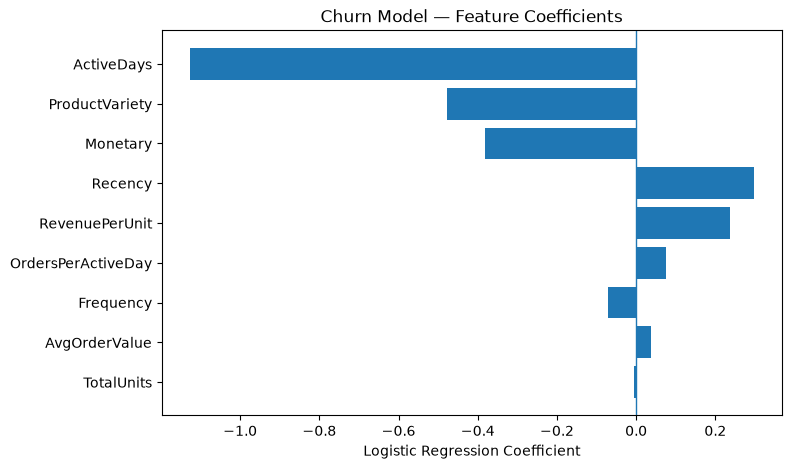

In [142]:
plt.figure(figsize=(8, 5))

plt.barh(
    coefficients['Feature'],
    coefficients['Coefficient']
)

plt.axvline(0, linewidth=1)

plt.gca().invert_yaxis()
plt.xlabel('Logistic Regression Coefficient')
plt.title('Churn Model — Feature Coefficients')

plt.show()

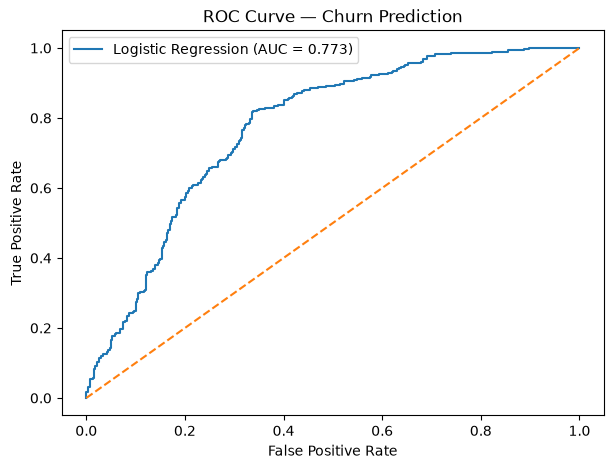

In [153]:
#ROC Curve 

from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f'Logistic Regression (AUC = {roc_auc_score(y_test, y_prob):.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — Churn Prediction')
plt.legend()

plt.show()

 OBSERVATION:

The Logistic Regression model associated higher ActiveDays, ProductVariety and Monetary with lower predicted churn probability, while higher Recency was associated with higher predicted churn probability

In [133]:
#Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['Recency','Frequency','Monetary',...,'ProductVariety', 'OrdersPerActiveDay','RevenuePerUnit']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For 

In [134]:
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

In [135]:
print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall   :", recall_score(y_test, y_pred_rf))
print("F1 Score :", f1_score(y_test, y_pred_rf))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Accuracy : 0.662704309063893
Precision: 0.6127946127946128
Recall   : 0.6190476190476191
F1 Score : 0.6159052453468697
ROC-AUC  : 0.7432062534776445

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.70      0.70       379
           1       0.61      0.62      0.62       294

    accuracy                           0.66       673
   macro avg       0.66      0.66      0.66       673
weighted avg       0.66      0.66      0.66       673


Confusion Matrix:
[[264 115]
 [112 182]]


In [136]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.named_steps['model'].feature_importances_
}).sort_values('Importance', ascending=False)

feature_importance

,Feature,Importance
2,Monetary,0.170255
0,Recency,0.156754
4,TotalUnits,0.153845
8,RevenuePerUnit,0.136331
3,AvgOrderValue,0.128431
6,ProductVariety,0.123564
5,ActiveDays,0.058114
1,Frequency,0.056696
7,OrdersPerActiveDay,0.016009


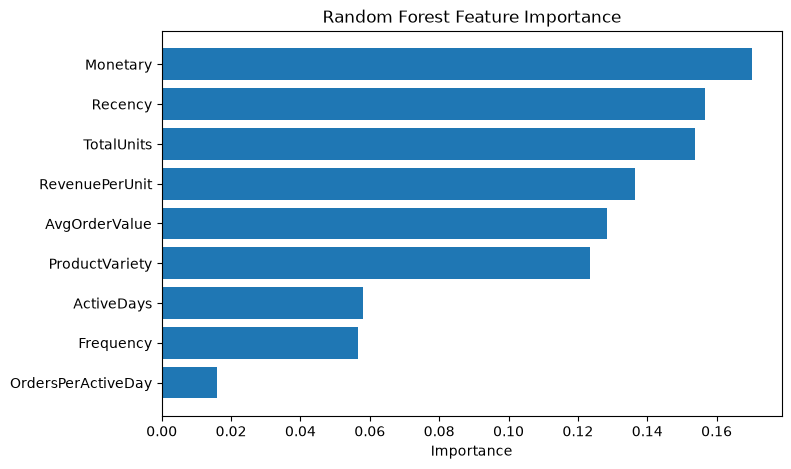

In [137]:

plt.figure(figsize=(8, 5))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.gca().invert_yaxis()
plt.xlabel('Importance')
plt.title('Random Forest Feature Importance')
plt.show()

In [138]:
#Gradient Boosting

from sklearn.ensemble import GradientBoostingClassifier

gb_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['Recency','Frequency','Monetary',...,'ProductVariety', 'OrdersPerActiveDay','RevenuePerUnit']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For 

In [139]:
y_pred_gb = gb_model.predict(X_test)
y_prob_gb = gb_model.predict_proba(X_test)[:, 1]

In [140]:
print("Accuracy :", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb))
print("Recall   :", recall_score(y_test, y_pred_gb))
print("F1 Score :", f1_score(y_test, y_pred_gb))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_gb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb))

Accuracy : 0.674591381872214
Precision: 0.6262626262626263
Recall   : 0.6326530612244898
F1 Score : 0.6294416243654822
ROC-AUC  : 0.7612585931470214

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.71      0.71       379
           1       0.63      0.63      0.63       294

    accuracy                           0.67       673
   macro avg       0.67      0.67      0.67       673
weighted avg       0.67      0.67      0.67       673


Confusion Matrix:
[[268 111]
 [108 186]]


# Churn probability for every customer

In [143]:
model_df['ChurnProbability'] = logistic_model.predict_proba(
    model_df.drop(columns=['CustomerID', 'Churn'])
)[:, 1]

In [144]:
model_df['RiskLevel'] = pd.cut(
    model_df['ChurnProbability'],
    bins=[0, 0.40, 0.70, 1.00],
    labels=['Low', 'Medium', 'High'],
    include_lowest=True
)

In [145]:
model_df[
    ['CustomerID', 'Recency', 'Frequency', 'Monetary',
     'ChurnProbability', 'RiskLevel']
].sort_values(
    'ChurnProbability',
    ascending=False
).head(20)

,CustomerID,Recency,Frequency,Monetary,ChurnProbability,RiskLevel
2889,17448.0,46,1,-4287.63,1.000000,High
1749,15369.0,46,1,-1592.49,0.999999,High
99,12503.0,239,1,-1126.00,0.999983,High
487,13154.0,46,1,-611.86,0.996664,High
1985,15802.0,44,3,-451.42,0.992827,High
642,13452.0,161,2,590.00,0.955872,High
3114,17850.0,204,35,5303.48,0.951827,High
2372,16500.0,232,1,165.00,0.919788,High
1826,15510.0,232,1,250.00,0.889383,High
3335,18233.0,227,1,440.00,0.873830,High


In [146]:
#Churn Risk Summary
risk_summary = (
    model_df['RiskLevel']
    .value_counts()
    .sort_index()
)

risk_summary

RiskLevel
Low       1290
Medium    1810
High       265
Name: count, dtype: int64

In [147]:
risk_summary_pct = (
    model_df['RiskLevel']
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

risk_summary_pct

RiskLevel
Low       38.34
Medium    53.79
High       7.88
Name: proportion, dtype: float64

In [148]:
#High-risk customers

high_risk_customers = (
    model_df[
        model_df['RiskLevel'] == 'High'
    ]
    [
        [
            'CustomerID',
            'Recency',
            'Frequency',
            'Monetary',
            'ProductVariety',
            'ActiveDays',
            'ChurnProbability',
            'RiskLevel'
        ]
    ]
    .sort_values(
        'ChurnProbability',
        ascending=False
    )
)

high_risk_customers.head(20)

,CustomerID,Recency,Frequency,Monetary,ProductVariety,ActiveDays,ChurnProbability,RiskLevel
2889,17448.0,46,1,-4287.63,1,1,1.000000,High
1749,15369.0,46,1,-1592.49,1,1,0.999999,High
99,12503.0,239,1,-1126.00,1,1,0.999983,High
487,13154.0,46,1,-611.86,1,1,0.996664,High
1985,15802.0,44,3,-451.42,1,1,0.992827,High
642,13452.0,161,2,590.00,1,2,0.955872,High
3114,17850.0,204,35,5303.48,24,3,0.951827,High
2372,16500.0,232,1,165.00,1,1,0.919788,High
1826,15510.0,232,1,250.00,1,1,0.889383,High
3335,18233.0,227,1,440.00,1,1,0.873830,High


In [149]:
#highest-value risky customers

model_df['RevenueAtRisk'] = (
    model_df['Monetary'] *
    model_df['ChurnProbability']
)
priority_customers = (
    model_df[
        model_df['RiskLevel'].isin(['Medium', 'High'])
    ]
    [
        [
            'CustomerID',
            'Recency',
            'Frequency',
            'Monetary',
            'ChurnProbability',
            'RiskLevel',
            'RevenueAtRisk'
        ]
    ]
    .sort_values(
        'RevenueAtRisk',
        ascending=False
    )
)

priority_customers.head(20)

,CustomerID,Recency,Frequency,Monetary,ChurnProbability,RiskLevel,RevenueAtRisk
3114,17850.0,204,35,5303.48,0.951827,High,5047.996080
1545,15032.0,158,5,4464.10,0.605701,Medium,2703.908140
2858,17396.0,50,6,4801.80,0.559844,Medium,2688.261248
60,12435.0,169,1,3978.99,0.669518,Medium,2664.003557
2387,16532.0,37,2,4516.80,0.464657,Medium,2098.764565
58,12433.0,268,2,3787.12,0.543221,Medium,2057.242028
474,13135.0,98,1,3096.00,0.625214,Medium,1935.662520
1209,14439.0,221,1,2661.24,0.687520,Medium,1829.656116
2114,16041.0,43,2,2739.80,0.613682,Medium,1681.366889
2511,16754.0,274,1,2002.40,0.759955,High,1521.733344


In [150]:
#Revenue exposure based on predicted churn probability

total_revenue_at_risk = model_df['RevenueAtRisk'].sum()

total_revenue = model_df['Monetary'].sum()

risk_percentage = (
    total_revenue_at_risk / total_revenue
) * 100

print("Total historical customer revenue:", total_revenue)
print("Estimated revenue at risk:", total_revenue_at_risk)
print("Revenue exposure:", risk_percentage)

Total historical customer revenue: 4941363.782
Estimated revenue at risk: 829126.090096757
Revenue exposure: 16.779296701793754


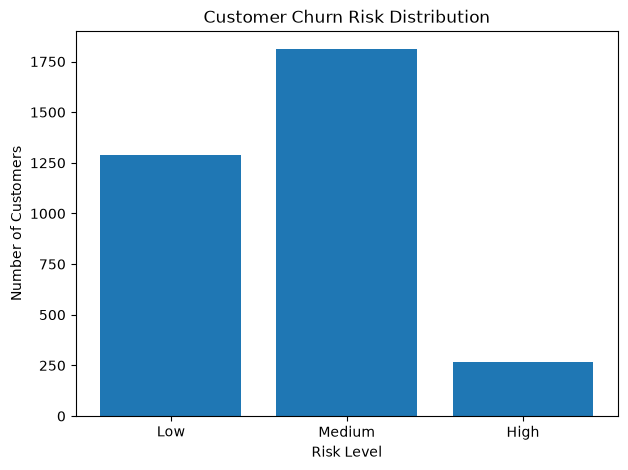

In [151]:
#Visualize the risk distribution
risk_counts = (
    model_df['RiskLevel']
    .value_counts()
    .reindex(['Low', 'Medium', 'High'])
)

plt.figure(figsize=(7, 5))

plt.bar(
    risk_counts.index,
    risk_counts.values
)

plt.xlabel('Risk Level')
plt.ylabel('Number of Customers')
plt.title('Customer Churn Risk Distribution')

plt.show()

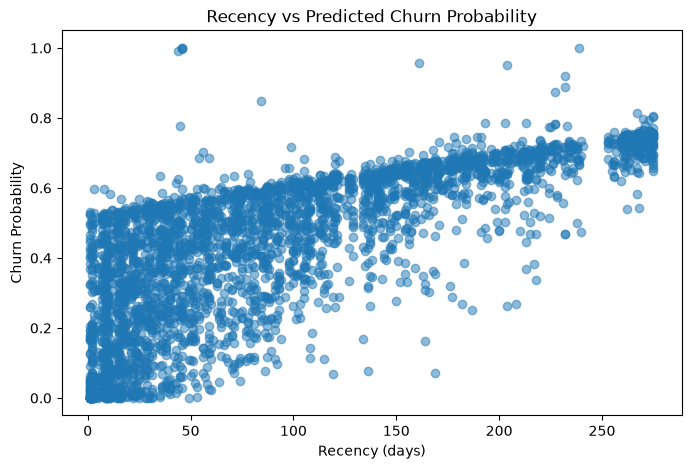

In [152]:
plt.figure(figsize=(8, 5))

plt.scatter(
    model_df['Recency'],
    model_df['ChurnProbability'],
    alpha=0.5
)

plt.xlabel('Recency (days)')
plt.ylabel('Churn Probability')
plt.title('Recency vs Predicted Churn Probability')

plt.show()